<a href="https://colab.research.google.com/github/aldogonzalez2006/Habit-streak/blob/main/Pr%C3%A1ctica1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 1. Autor: Aldo Cervantes González




# 1. Introducción a Python


## (a) Ejercicios

Print para imprimir, type para mostrar sus tipos.
Aquí podemos destacar el tipo complex que se identifica al resto por definir j, el resto muy similar a otros lenguajes que ya conocemos.

In [123]:
## Ejercicio I
entero = 1
decimal = 1.5
complejo = 1 + 1j
cadena = "Esto es una cadena"
booleano = True

print(entero, decimal, complejo, cadena, booleano)
type (entero), type (decimal), type (complejo), type (cadena), type (booleano)

1 1.5 (1+1j) Esto es una cadena True


(int, float, complex, str, bool)

Como vimos en la primera clase de laboratorio, python ya conoce que operación hacer según su simbolo, así que solo las imprimimos.

In [124]:
## Ejercicio II
a=7
b=2

## Imprimimos las operaciones
print("Suma:", a+b)
print("Resta:", a-b)
print("Multiplicación:", a*b)
print("División:", a/b)
print("Potencia:", a**b)
print("Residuo:", a%b)

Suma: 9
Resta: 5
Multiplicación: 14
División: 3.5
Potencia: 49
Residuo: 1


En Python usar comillas simples '' significa al igual que "" definir una cadenas por lo que al escribir 3*'0', esta diciendo a la máquina "escribe esto (lo que esta en comillas), esta cantidad de veces (el entero antes del *)

In [125]:
print ("3 * 0", 3 * 0)
print ("3*'0'", 3 * '0')

3 * 0 0
3*'0' 000


In [126]:
lista = [10, 20, 30, 40, 50]

lista.append (60)
lista.append (70)

lista[0] = 11

print("Ultimo elemento:", lista[-1])
print("Primeros 3 elementos: ", lista [0:3])

Ultimo elemento: 70
Primeros 3 elementos:  [11, 20, 30]


## (b) Define una función que al ingresarle 2 matrices, te devuelva los 2 productos matriciales

Implementamos la multiplicación de matrices en ambos sentidos, A * B y B * A para verificar la compatibilidad de sus dimensiones y analizar la propiedad de no conmutatividad.

In [127]:
def multiplicar_matrices(A, B):
    # Verificamos que el número de columnas de A sea igual al numero de filas de B
    if len(A[0]) != len(B):
        return None

    filas_A, col_A = len(A), len(A[0])
    col_B = len(B[0])

    # Inicializamos la matriz resultado con ceros
    C = [[0] * col_B for _ in range(filas_A)]

    # Calculamos el producto punto
    for i in range(filas_A):
        for j in range(col_B):
            for k in range(col_A):
                C[i][j] += A[i][k] * B[k][j]

    return C


def evaluar_productos_cruzados(A, B):
    # Aplica la multiplicación en ambos sentidos (A*B y B*A) y muestra los resultados.
    casos = [("A x B", multiplicar_matrices(A, B)),
             ("B x A", multiplicar_matrices(B, A))]

    for i, res in casos:
        print(f"Resultado {i}")
        if res is not None:
            for fila in res:
                print(fila)
        else:
            print("No se puede calcular: Dimensiones incompatibles.")
        print()



Prueba con dos matrices de dimensiones compatibles.

In [128]:
# Definición de matrices de prueba
matriz_A = [
    [1, 2, 3],
    [4, 5, 6]
]  # Dimensión 2x3

matriz_B = [
    [7, 8],
    [9, 1],
    [2, 3]
]  # Dimensión 3x2

# Ejecución del caso de prueba
evaluar_productos_cruzados(matriz_A, matriz_B)

Resultado A x B
[31, 19]
[85, 55]

Resultado B x A
[39, 54, 69]
[13, 23, 33]
[14, 19, 24]



## (c) Define una función que dadas la posición inicial, final y el tiempo que le tome a la persona, recuperemos la velocidad

Definimos una función que calcula la velocidad a partir de la posición inicial ($\vec{r}_0$), la posición final ($\vec{r}_f$) y el intervalo de tiempo ($t$).
La función maneja tanto posiciones escalares/unidimensionales como vectoriales. Utlizo la palabra raise para lanzar excepciones, Y el método isinstance para verificar si un objeto o variable pertenece a un tipo de dato específico, en este caso utilicé para decidir si las posiciones ingresadas eran números simples (escalares 1D) o listas con componentes (vectores 2D/3D).


In [129]:
def calcular_velocidad(r_inicial, r_final, tiempo):
    # Calcula la velocidad dado el cambio de posición y el tiempo transcurrido
    if tiempo <= 0:
        raise ValueError("El tiempo transcurrido debe ser mayor que cero.")

    # Si las posiciones son multidimensional (listas o vectores)
    if isinstance(r_inicial, (list, tuple)) and isinstance(
        r_final, (list, tuple)
    ):
        if len(r_inicial) != len(r_final):
            raise ValueError(
                "Las posiciones inicial y final deben tener la misma dimensión."
            )

        # Calculamos la diferencia componente a componente
        velocidad = [(r_f - r_i) / tiempo for r_i, r_f in zip(r_inicial, r_final)]
        return velocidad

    # Caso escalar (1D)
    return (r_final - r_inicial) / tiempo

Prueba del ejercicio:
Verificamos el funcionamiento de la función tanto para movimiento en 1D como para vectores de posición en 2D/3D.

In [130]:
# Caso 1: Movimiento en 1D
r0_1d, rf_1d, t_1d = 5.0, 25.0, 4.0
v_1d = calcular_velocidad(r0_1d, rf_1d, t_1d)
print(f"Velocidad 1D: {v_1d} m/s")

# Caso 2: Movimiento vectorial (2D)
r0_2d = [1.0, 2.0]
rf_2d = [7.0, 10.0]
t_2d = 3.0
v_2d = calcular_velocidad(r0_2d, rf_2d, t_2d)
print(f"Vector velocidad 2D: {v_2d} m/s")

Velocidad 1D: 5.0 m/s
Vector velocidad 2D: [2.0, 2.6666666666666665] m/s


## (d) Clasificación temperaturas

In [131]:
def clasificar_temperatura(temp):
    # Clasifica una temperatura según las especificaciones de rango
    if temp < 0:
        return "Menor que 0"
    elif temp <= 30:
        return "Entre 0 y 30"
    else:
        return "Mayor que 30"


# Definimos lista
temperaturas = [-20, 0, 15, 25, 37, 100]

# Inicializmaos en 0 para guardar las categorías y realizar el conteo
categorias_guardadas = []
conteo_menor_0 = 0
conteo_0_a_30 = 0
conteo_mayor_30 = 0

# Recorremos la lista
for temp in temperaturas:
    categoria = clasificar_temperatura(temp)
    categorias_guardadas.append(categoria)

    # Conteo acumulativo
    if categoria == "Menor que 0":
        conteo_menor_0 += 1
    elif categoria == "Entre 0 y 30":
        conteo_0_a_30 += 1
    else:
        conteo_mayor_30 += 1

# Resultados

print("\nConteo de temperaturas:")
print(f"  Menor que 0: {conteo_menor_0}")
print(f"  Entre 0 y 30: {conteo_0_a_30}")
print(f"  Mayor que 30: {conteo_mayor_30}")


Conteo de temperaturas:
  Menor que 0: 1
  Entre 0 y 30: 3
  Mayor que 30: 2


Diseña ejemplos que detecten si programaste
incorrectamente alguno de los extremos.

In [132]:
# Definición de pruebas en los límites
pruebas_extremos = [-0.1, 0, 30, 30.1]

print("Pruebas:")
for t in pruebas_extremos:
    print(f"Temperatura {t}°C -> Clasificación: '{clasificar_temperatura(t)}'")

Pruebas:
Temperatura -0.1°C -> Clasificación: 'Menor que 0'
Temperatura 0°C -> Clasificación: 'Entre 0 y 30'
Temperatura 30°C -> Clasificación: 'Entre 0 y 30'
Temperatura 30.1°C -> Clasificación: 'Mayor que 30'


## (e) Problema de basileia [1]

Consiste en encontrar la suma exacta de los inversos de los cuadrados de todos los números enteros positivos, es decir, calcular la suma de la serie infinita:$$\sum_{n=1}^{\infty} \frac{1}{n^2} = 1 + \frac{1}{4} + \frac{1}{9} + \frac{1}{16} + \frac{1}{25} + \dots$$
Fue en 1644 por Pietro Mengoli en 1644 y fue resuelto hasta 1735 por Leonhard Euler  demostrando de forma sorprendente que la suma converge exactamente a:$$\frac{\pi^2}{6} \approx 1.6449340668482264$$

Utilizaremos un ciclo for para aproximar numéricamente esta suma sumando los primeros $N$ términos y comparándola con el valor exacto teorizado por Euler.

In [133]:
#Libreria para utilizar pi
import math

# Número de términos para la aproximación
N = 1000000

# Variable acumuladora para la suma
suma_basilea = 0.0

# Ciclo for para actualizar la variable término a término
for n in range(1, N + 1):
    suma_basilea += 1 / (n**2)

# Valor exacto según la solución de Euler
valor_teorico = (math.pi**2) / 6

# Resultados
print(f"Aproximación con N = {N:,} términos: {suma_basilea:.12f}")
print(f"Resultado de Euler:           {valor_teorico:.12f}")

Aproximación con N = 1,000,000 términos: 1.644933066849
Resultado de Euler:           1.644934066848


## (f) Suma de Riemann [2]

Es un método para aproximar el área total bajo la curva de una función $f(x)$ dividiendo una región en múltiples subintervalos (rectángulos) más pequeños, calculando el área de cada uno y sumándolas. Conforme el número de subintervalos $n$ tiende al infinito ($n \to \infty$), el ancho de los rectángulos tiende a cero y la suma de Riemann converge exactamente al valor de la integral definida de la función:$$\int_a^b f(x) \, dx = \lim_{n \to \infty} \sum_{i=1}^{n} f(x_i^*) \Delta x$$
donde:$\Delta x = \frac{b - a}{n}$ es el ancho de cada subintervalo y $x_i^* = a + i \cdot \Delta x$ es el punto de evaluación (usando el extremo derecho).

Esto lo vemos en mate IV por eso pongo de referencia el libro en el que se baso mi curso.

In [134]:

# Introduzco numpy por primera vez
import numpy as np


def suma_riemann_derecha(f, a, b, n):
    """Calcula la suma de Riemann evaluando en el extremo derecho."""
    dx = (b - a) / n
    x = np.linspace(a + dx, b, n)
    return np.sum(f(x) * dx)


# Función f(x) = sin(x) + x^2 e intervalo [0, pi]
f = lambda x: np.sin(x) + (x**2)
a, b = 0, np.pi
valor_exacto = 2 + (np.pi**3) / 3

print(f"Valor teórico exacto (2 + pi^3 / 3): {valor_exacto:.8f}\n")

# Evaluación con distinto número de particiones (N)
for n in [10, 100, 1000, 100000]:
    aprox = suma_riemann_derecha(f, a, b, n)
    error = abs(valor_exacto - aprox)
    print(f"N = {n:6d} | Suma de Riemann: {aprox:.8f}")

Valor teórico exacto (2 + pi^3 / 3): 12.33542556

N =     10 | Suma de Riemann: 13.92094006
N =    100 | Suma de Riemann: 12.49080922
N =   1000 | Suma de Riemann: 12.35093222
N = 100000 | Suma de Riemann: 12.33558059


# 2. Matplotlib

## (a) Gráficas de funciones
En este ejercicio definimos y graficamos distintas funciones matemáticas básicas, superpuestas y exponenciales utilizando NumPy y Matplotlib.

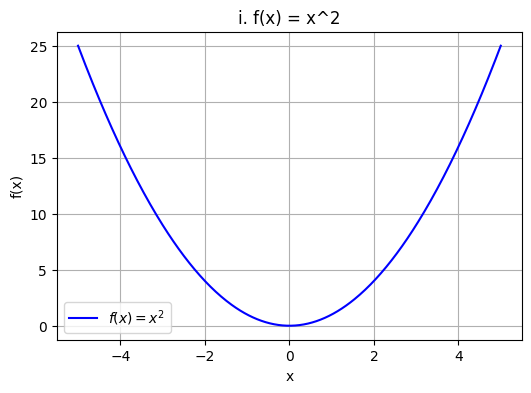

In [135]:
#Importamos las librerias
import matplotlib.pyplot as plt
import numpy as np

# Definición del dominio
x = np.linspace(-5, 5, 400)

# i. f(x) = x^2
plt.figure(figsize=(6, 4))
plt.plot(x, x**2, label=r"$f(x) = x^2$", color="blue")
plt.title("i. f(x) = x^2")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.legend()
plt.show()



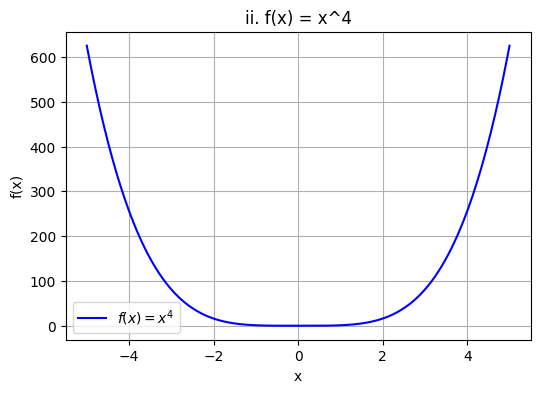

In [136]:
# ii. f(x) = x^4
plt.figure(figsize=(6, 4))
plt.plot(x, x**4, label=r"$f(x) = x^4$", color="blue")
plt.title("ii. f(x) = x^4")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.legend()
plt.show()



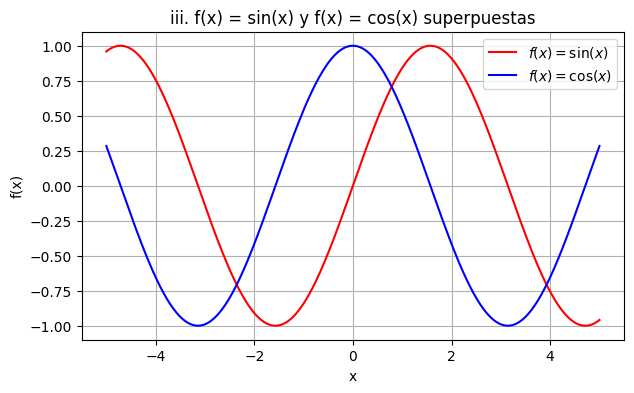

In [137]:
# iii. f(x) = sin(x) y f(x) = cos(x) superpuestas
plt.figure(figsize=(7, 4))
plt.plot(x, np.sin(x), label=r"$f(x) = \sin(x)$", color="red")
plt.plot(x, np.cos(x), label=r"$f(x) = \cos(x)$", color="blue")
plt.title("iii. f(x) = sin(x) y f(x) = cos(x) superpuestas")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.legend()
plt.show()



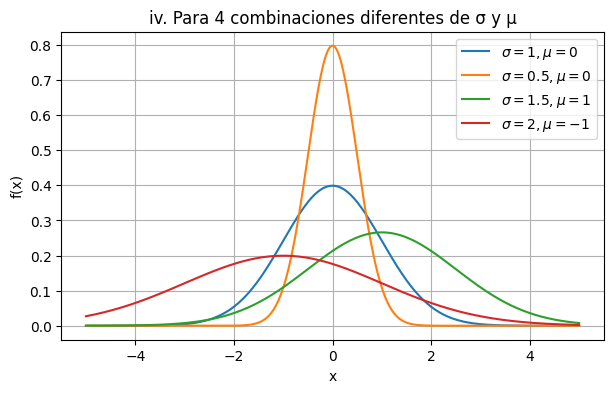

In [138]:
# iv. Para 4 combinaciones diferentes de sigma y mu
plt.figure(figsize=(7, 4))
combinaciones = [(1, 0), (0.5, 0), (1.5, 1), (2, -1)]  # (sigma, mu)

for sigma, mu in combinaciones:
    gaussiana = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
        -((x - mu) ** 2) / (2 * sigma**2)
    )
    plt.plot(x, gaussiana, label=rf"$\sigma={sigma}, \mu={mu}$")

plt.title("iv. Para 4 combinaciones diferentes de σ y μ")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.legend()
plt.show()



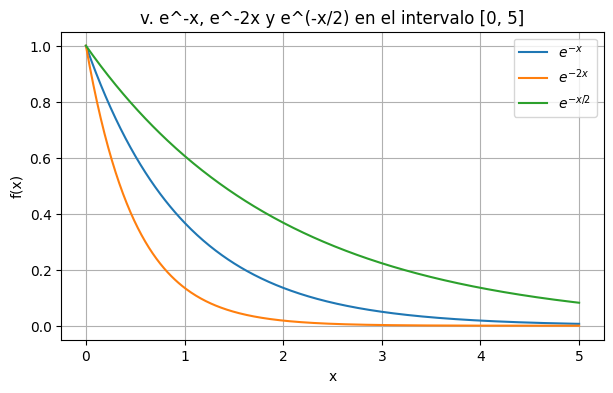

In [139]:

# v. e^-x, e^-2x y e^(-x/2) en el intervalo [0, 5]
x_exp = np.linspace(0, 5, 400)
plt.figure(figsize=(7, 4))
plt.plot(x_exp, np.exp(-x_exp), label=r"$e^{-x}$")
plt.plot(x_exp, np.exp(-2 * x_exp), label=r"$e^{-2x}$")
plt.plot(x_exp, np.exp(-x_exp / 2), label=r"$e^{-x/2}$")
plt.title(r"v. e^-x, e^-2x y e^(-x/2) en el intervalo [0, 5]")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.legend()
plt.show()

## (b) Distribución Normal 2D y Puntos en Circunferencias [3]

1. np.random.normal y distribución normal 2D:
   - np.random.normal(loc, scale, size): genera números aleatorios a partir de una distribución gaussiana con media $\mu$ loc y desviación estándar $\sigma$ scale.
   - Una distribución normal en 2 dimensiones genera pares de coordenadas $(X, Y)$ independientes, donde cada eje sigue una distribución normal. Al graficar las duplas, los puntos forman una "nube" densa centrada en $(\mu_x, \mu_y)$, cuya dispersión depende de $\sigma$.

2. ¿Qué observamos y por qué?
   - Observamos las nubes de puntos de cada par $(\sigma, \mu)$ se agrupan en regiones separadas del plano y tienen diferentes concentraciones.
   - Esto ocurre porque el parámetro $\mu$ desplaza el centro de la nube en el plano 2D, mientras que $\sigma$ controla qué tan dispersos o concentrados están los puntos alrededor de ese centro.

<>:26: SyntaxWarning: invalid escape sequence '\s'
<>:26: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2888/2823135195.py:26: SyntaxWarning: invalid escape sequence '\s'
  plt.title("Distribución Normal 2D para varios ($\sigma, \mu$)")


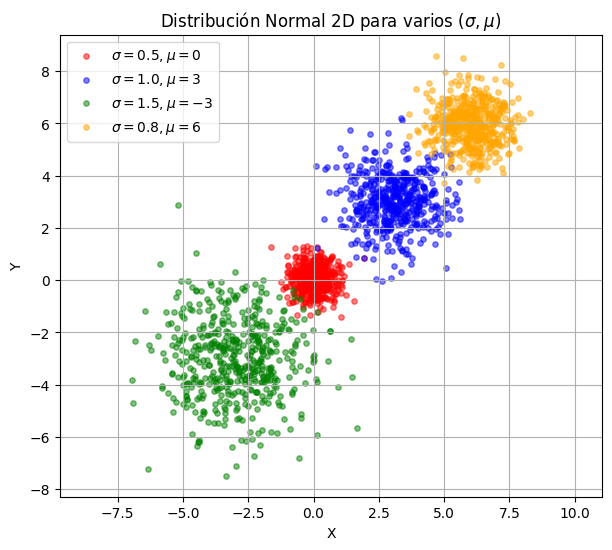

In [140]:
import matplotlib.pyplot as plt
import numpy as np

# Parte 1: Generación de n pares para distintas combinaciones de (sigma, mu)
n = 500
parametros = [
    (0.5, 0, "red"),
    (1.0, 3, "blue"),
    (1.5, -3, "green"),
    (0.8, 6, "orange"),
]

plt.figure(figsize=(7, 6))
for sigma, mu, color in parametros:
    x_g = np.random.normal(loc=mu, scale=sigma, size=n)
    y_g = np.random.normal(loc=mu, scale=sigma, size=n)
    plt.scatter(
        x_g,
        y_g,
        alpha=0.5,
        c=color,
        label=rf"$\sigma={sigma}, \mu={mu}$",
        s=15,
    )

plt.title("Distribución Normal 2D para varios ($\sigma, \mu$)")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.legend()
plt.axis("equal")
plt.show()



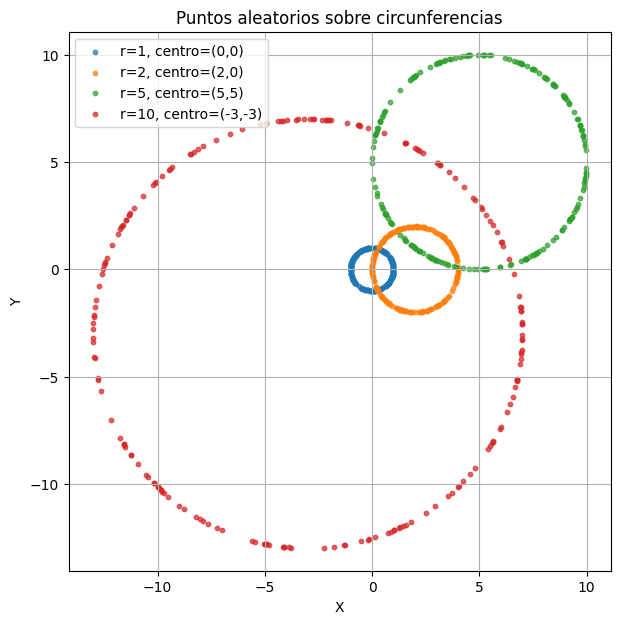

In [141]:
# Parte 2: M puntos aleatorios distribuidos en circunferencias
M = 200
radios = [1, 2, 5, 10]
centros = [(0, 0), (2, 0), (5, 5), (-3, -3)]

plt.figure(figsize=(7, 7))
for r, (cx, cy) in zip(radios, centros):
    # Generamos ángulos aleatorios uniformes entre 0 y 2*pi
    theta = np.random.uniform(0, 2 * np.pi, M)
    x_circ = cx + r * np.cos(theta)
    y_circ = cy + r * np.sin(theta)
    plt.scatter(
        x_circ,
        y_circ,
        s=10,
        label=f"r={r}, centro=({cx},{cy})",
        alpha=0.7,
    )

plt.title("Puntos aleatorios sobre circunferencias")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.legend()
plt.axis("equal")
plt.show()

## (c) Cociente de diferencias centradas

1. **¿Qué es y de dónde surge?**
   - El cociente de diferencias centradas $D_h f(x) = \frac{f(x+h) - f(x-h)}{2h}$ es un método de diferenciación numérica para aproximar la derivada de una función.
   - Surge de la serie de Taylor al expandir $f(x+h)$ y $f(x-h)$ alrededor de $x$. Al restar ambas expansiones, los términos pares se cancelan, lo que genera un error de aproximación de orden $O(h^2)$, siendo más preciso que las diferencias hacia adelante o hacia atrás.

2. **Relación con la definición de derivada:**
   - La definición formal de derivada es el límite $\lim_{h \to 0} \frac{f(x+h)-f(x)}{h}$.
   - El cociente centrado toma una simetría alrededor de $x$ usando un paso finito $h > 0$. A medida que $h \to 0$, $D_h f(x) \to f'(x)$.

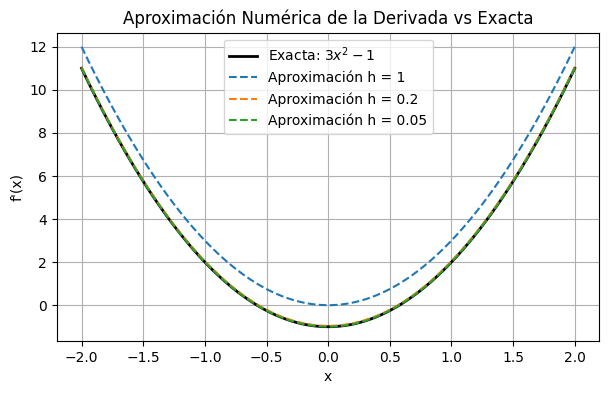

In [142]:
import matplotlib.pyplot as plt
import numpy as np


# Definición de la función y su derivada exacta
def f(x):
    return x**3 - x


def f_derivada_exacta(x):
    return 3 * (x**2) - 1


def diferencias_centradas(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)


# Dominio
x = np.linspace(-2, 2, 400)

# Comparación gráfica de aproximaciones de la derivada
plt.figure(figsize=(7, 4))
plt.plot(
    x,
    f_derivada_exacta(x),
    "k-",
    linewidth=2,
    label=r"Exacta: $3x^2 - 1$",
)

pasos_h = [1, 0.2, 0.05]
for h in pasos_h:
    aprox = diferencias_centradas(f, x, h)
    plt.plot(x, aprox, "--", label=f"Aproximación h = {h}")

plt.title("Aproximación Numérica de la Derivada vs Exacta")
plt.xlabel("x")
plt.ylabel("f'(x)")
plt.grid(True)
plt.legend()
plt.show()



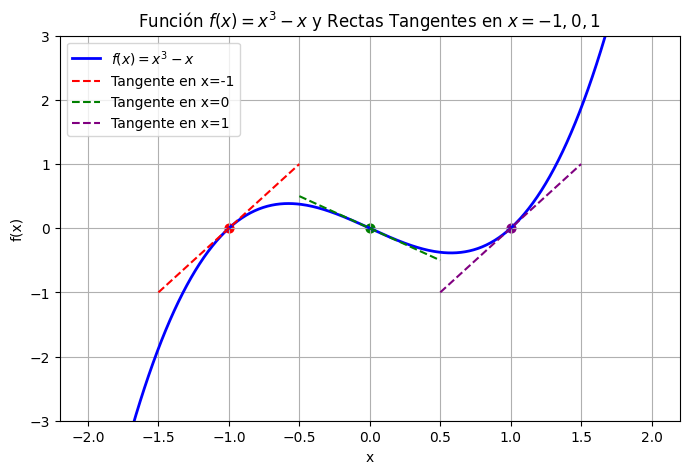

In [143]:
import matplotlib.pyplot as plt
import numpy as np

# Gráfica de f(x) con rectas tangentes en x = -1, 0, 1
plt.figure(figsize=(8, 5))
plt.plot(
    x,
    f(x),
    label=r"$f(x) = x^3 - x$",
    color="blue",
    linewidth=2,
)

puntos = [-1, 0, 1]
colores_tangente = ["red", "green", "purple"]

for x0, color in zip(puntos, colores_tangente):
    y0 = f(x0)
    m = f_derivada_exacta(x0)  # Pendiente de la tangente
    # Ecuación de la recta tangente: y = m*(x - x0) + y0
    x_tang = np.linspace(x0 - 0.5, x0 + 0.5, 50)
    y_tang = m * (x_tang - x0) + y0

    plt.plot(x_tang, y_tang, color=color, linestyle="--", label=f"Tangente en x={x0}")
    plt.scatter([x0], [y0], color=color, s=40)

plt.title(r"Función $f(x) = x^3 - x$ y Rectas Tangentes en $x = -1, 0, 1$")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.ylim(-3, 3)
plt.grid(True)
plt.legend()
plt.show()

# 3. Numpy

La siguiente forma de resolver el inciso (a) será primero definiendo el tema de algebra lineal que estamos utilizando para dicho ejercicio i, ii, ..., vii, para saber precisamente que estamos haciendo, despues en otra celda lo que se pide para el codigo, y la tercera celda será ya el código en donde ya toma mas sentido la explicacion en la celda 1

## (a) Un número complejo $z$ tiene la forma $a + bi$, donde $a$ es la parte real y $b$ es la parte imaginaria, como ya vimos, en python utilizamos $j$ para la unidad imaginaria.

Conjugado ($\bar{z}$ o $z^*$): Le cambia el signo a la parte imaginaria. Si $z = a + bi$, entonces $\bar{z} = a - bi$.

Módulo ($\vert{}z\vert{}$): Es la longitud o distancia desde el origen al punto $(a,b)$ en el plano complejo: $\vert{}z\vert{} = \sqrt{a^2 + b^2}$.

 i.
Dados $z_1 = 3 + 4i$ y $z_2 = 1 - 2i$, calculamos sus operaciones aritméticas fundamentales, partes reales e imaginarias, conjugados y módulos mediante NumPy.

In [144]:
import numpy as np

# Definición de los números complejos
z1 = complex(3, 4)  # 3 + 4j
z2 = complex(1, -2)  # 1 - 2j

# 1. Operaciones básicas
suma = z1 + z2
diferencia = z1 - z2
producto = z1 * z2
cociente = z1 / z2

print("--- Operaciones Básicas ---")
print(f"Suma (z1 + z2):       {suma}")
print(f"Diferencia (z1 - z2): {diferencia}")
print(f"Producto (z1 * z2):   {producto}")
print(f"Cociente (z1 / z2):   {cociente}\n")

# 2. Partes reales e imaginarias
print("--- Partes Reales e Imaginarias ---")
print(f"Re(z1): {np.real(z1)}, Im(z1): {np.imag(z1)}")
print(f"Re(z2): {np.real(z2)}, Im(z2): {np.imag(z2)}\n")

# 3. Conjugados y Módulos
print("--- Conjugados y Módulos ---")
print(f"Conjugado z1*: {np.conj(z1)}")
print(f"Conjugado z2*: {np.conj(z2)}")
print(f"Módulo |z1|:   {np.abs(z1)}")
print(f"Módulo |z2|:   {np.abs(z2)}")

--- Operaciones Básicas ---
Suma (z1 + z2):       (4+2j)
Diferencia (z1 - z2): (2+6j)
Producto (z1 * z2):   (11-2j)
Cociente (z1 / z2):   (-1+2j)

--- Partes Reales e Imaginarias ---
Re(z1): 3.0, Im(z1): 4.0
Re(z2): 1.0, Im(z2): -2.0

--- Conjugados y Módulos ---
Conjugado z1*: (3-4j)
Conjugado z2*: (1+2j)
Módulo |z1|:   5.0
Módulo |z2|:   2.23606797749979


ii.
Todo número complejo $z = x + iy$ se puede representar en forma polar: $z = r e^{i\theta}$, donde: $r = \vert{}z\vert{} = \sqrt{x^2 + y^2}$ es el módulo (magnitud).$\theta = \arg(z) = \text{atan2}(y, x)$ es el argumento (ángulo en radianes). Por la Fórmula de Euler, $e^{i\theta} = \cos(\theta) + i \sin(\theta)$, reconstruimos el número como $z = r(\cos\theta + i\sin\theta)$.

ii. Calculamos el módulo $r = |z|$ y el argumento $\theta = \arg(z)$ para los números dados, y los reconstruimos mediante $z = r e^{i\theta}$.

In [145]:
# Lista de números complejos dados
numeros = [complex(1, 1), complex(-1, 1), complex(-2, -2), complex(3, -4)]

print("=== Reconstrucción mediante r * e^(i * theta) ===")
for z in numeros:
    r = np.abs(z)  # Módulo
    theta = np.angle(z)  # Argumento en radianes

    # Reconstrucción con r * exp(i * theta)
    z_reconstruido = r * np.exp(1j * theta)

    print(f"\nOriginal z = {z}")
    print(f"  Módulo r = {r:.4f}")
    print(f"  Ángulo θ = {theta:.4f} rad ({np.degrees(theta):.1f}°)")
    print(f"  Reconstruido: {z_reconstruido:.4f}")
    print(
        f"  ¿Coinciden?: {np.isclose(z, z_reconstruido)}"
    )  # Verificación numérica

=== Reconstrucción mediante r * e^(i * theta) ===

Original z = (1+1j)
  Módulo r = 1.4142
  Ángulo θ = 0.7854 rad (45.0°)
  Reconstruido: 1.0000+1.0000j
  ¿Coinciden?: True

Original z = (-1+1j)
  Módulo r = 1.4142
  Ángulo θ = 2.3562 rad (135.0°)
  Reconstruido: -1.0000+1.0000j
  ¿Coinciden?: True

Original z = (-2-2j)
  Módulo r = 2.8284
  Ángulo θ = -2.3562 rad (-135.0°)
  Reconstruido: -2.0000-2.0000j
  ¿Coinciden?: True

Original z = (3-4j)
  Módulo r = 5.0000
  Ángulo θ = -0.9273 rad (-53.1°)
  Reconstruido: 3.0000-4.0000j
  ¿Coinciden?: True


iii. Buscamos un complejo $z = a + bi$ sabiendo que $a = 3$ y $\vert{}z\vert{} = 5$.Por definición de módulo:$$\vert{}z\vert{} = \sqrt{a^2 + b^2} = 5 \implies 3^2 + b^2 = 25 \implies 9 + b^2 = 25 \implies b^2 = 16 \implies b = \pm 4$$Por lo tanto, existen dos soluciones: $z = 3 + 4i$ y $z = 3 - 4i$.

iii. Encuentra todos los números complejos z de mórulo 5 cuya parte real sea 3. Construye los
resultados en NumPy y verifícalo.

In [146]:
# Construcción de los dos posibles resultados
z_sol1 = complex(3, 4)
z_sol2 = complex(3, -4)

soluciones = [z_sol1, z_sol2]

print("Soluciones")
for i, z in enumerate(soluciones, 1):
    mod = np.abs(z)
    real_part = np.real(z)
    print(f"Solución {i}: z = {z}")
    print(f"  Parte real: {real_part} (¿Es 3?: {real_part == 3})")
    print(f"  Módulo: {mod} (¿Es 5?: {mod == 5})")

Soluciones
Solución 1: z = (3+4j)
  Parte real: 3.0 (¿Es 3?: True)
  Módulo: 5.0 (¿Es 5?: True)
Solución 2: z = (3-4j)
  Parte real: 3.0 (¿Es 3?: True)
  Módulo: 5.0 (¿Es 5?: True)


iv. Valores aleatorios de $\theta$, Fórmula de Euler y Plano Complejo:
Generamos 50 ángulos aleatorios $\theta \in [0, 2\pi)$.La Fórmula de Euler dice que $e^{i\theta} = \cos(\theta) + i\sin(\theta)$. Como el módulo de $e^{i\theta}$ es $\vert{}e^{i\theta}\vert{} = \sqrt{\cos^2\theta + \sin^2\theta} = 1$, al graficar estos números en el plano complejo (Eje X = Real, Eje Y = Imaginario), todos caen exactamente sobre la circunferencia unitaria de radio 1.

¿Qué observación notas aquí?
Todos los números de la forma $e^{i\theta}$ se encuentran sobre la circunferencia de radio 1 (círculo unitario) en el plano complejo. Esto ocurre porque multiplicaciones por fases puras $e^{i\theta}$ únicamente cambian el ángulo (fase) sin alterar la magnitud del vector.

Diferencia máxima entre e^(iθ) y cos(θ) + i*sin(θ): 0.0


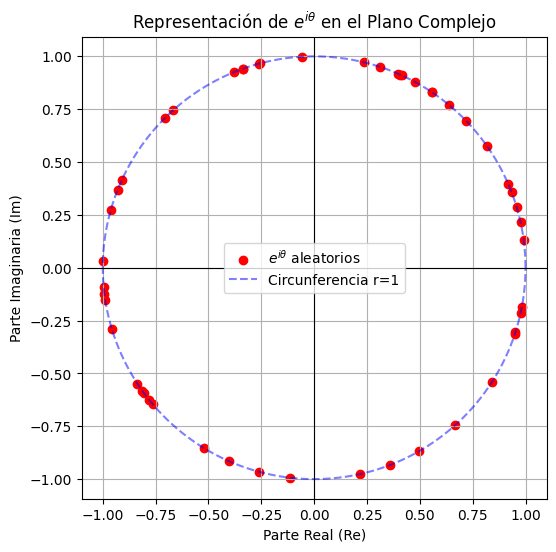

In [147]:
import matplotlib.pyplot as plt

# Generar 50 ángulos aleatorios
np.random.seed(42)
thetas = np.random.uniform(0, 2 * np.pi, 50)

# Calculamos e^(i*theta) y cos(theta) + i*sin(theta)
e_itheta = np.exp(1j * thetas)
euler_form = np.cos(thetas) + 1j * np.sin(thetas)

# Verificación de la diferencia numérica entre ambas expresiones
diferencia_maxima = np.max(np.abs(e_itheta - euler_form))
print(f"Diferencia máxima entre e^(iθ) y cos(θ) + i*sin(θ): {diferencia_maxima}")

# Graficación en el plano complejo
plt.figure(figsize=(6, 6))
plt.scatter(
    np.real(e_itheta),
    np.imag(e_itheta),
    color="red",
    label=r"$e^{i\theta}$ aleatorios",
)

# Dibujamos el círculo unitario de referencia
t = np.linspace(0, 2 * np.pi, 200)
plt.plot(np.cos(t), np.sin(t), "b--", alpha=0.5, label="Circunferencia r=1")

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.title(r"Representación de $e^{i\theta}$ en el Plano Complejo")
plt.xlabel("Parte Real (Re)")
plt.ylabel("Parte Imaginaria (Im)")
plt.grid(True)
plt.axis("equal")
plt.legend()
plt.show()

v. Demostración y Verificación de $\vert{}z \cdot w\vert{} = \vert{}z\vert{} \cdot \vert{}w\vert{}$ Demostración analítica: Sean $z = r_1 e^{i\theta_1}$ y $w = r_2 e^{i\theta_2}$. El producto es $z \cdot w = (r_1 r_2) e^{i(\theta_1 + \theta_2)}$. Tomando módulo: $\vert{}z \cdot w\vert{} = r_1 r_2 = \vert{}z\vert{} \cdot \vert{}w\vert{}$.

v. Demostración y Verificación de $|zw| = |z||w|$

Demostración analítica:
Expresando $z$ y $w$ en forma polar $z = |z|e^{i\theta_z}$ y $w = |w|e^{i\theta_w}$:
$$|zw| = \left| (|z|e^{i\theta_z}) (|w|e^{i\theta_w}) \right| = \left| |z||w| e^{i(\theta_z + \theta_w)} \right| = |z||w| \underbrace{|e^{i(\theta_z + \theta_w)}|}_{1} = |z||w|$$

In [148]:
# Generamos 10 parejas de números complejos aleatorios
z_array = np.random.uniform(-10, 10, 10) + 1j * np.random.uniform(-10, 10, 10)
w_array = np.random.uniform(-10, 10, 10) + 1j * np.random.uniform(-10, 10, 10)

print("=== Verificación de |zw| = |z||w| ===")
cumple_todos = True
for i, (z, w) in enumerate(zip(z_array, w_array), 1):
    lhs = np.abs(z * w)  # |z * w|
    rhs = np.abs(z) * np.abs(w)  # |z| * |w|
    coinciden = np.isclose(lhs, rhs)
    if not coinciden:
        cumple_todos = False
    print(f"Pareja {i:2d}: |z*w| = {lhs:.6f} | |z|*|w| = {rhs:.6f} | ¿Iguales?: {coinciden}")

print(f"\n¿Se cumplió en las 10 parejas?: {cumple_todos}")

=== Verificación de |zw| = |z||w| ===
Pareja  1: |z*w| = 87.607213 | |z|*|w| = 87.607213 | ¿Iguales?: True
Pareja  2: |z*w| = 46.583375 | |z|*|w| = 46.583375 | ¿Iguales?: True
Pareja  3: |z*w| = 114.728506 | |z|*|w| = 114.728506 | ¿Iguales?: True
Pareja  4: |z*w| = 90.472451 | |z|*|w| = 90.472451 | ¿Iguales?: True
Pareja  5: |z*w| = 26.894110 | |z|*|w| = 26.894110 | ¿Iguales?: True
Pareja  6: |z*w| = 48.866177 | |z|*|w| = 48.866177 | ¿Iguales?: True
Pareja  7: |z*w| = 77.639117 | |z|*|w| = 77.639117 | ¿Iguales?: True
Pareja  8: |z*w| = 76.750025 | |z|*|w| = 76.750025 | ¿Iguales?: True
Pareja  9: |z*w| = 102.697221 | |z|*|w| = 102.697221 | ¿Iguales?: True
Pareja 10: |z*w| = 79.687430 | |z|*|w| = 79.687430 | ¿Iguales?: True

¿Se cumplió en las 10 parejas?: True


vi. Demostración y Verificación de $(z + w)^ = z^ + w^*$Demostración analítica:Sean $z = a + bi$ y $w = c + di$. Suma: $z + w = (a + c) + (b + d)i$.
 Conjugado de la suma: $(z + w)^* = (a + c) - (b + d)i$. Suma de conjugados: $z^* + w^* = (a - bi) + (c - di) = (a + c) - (b + d)i$.Ambas expresiones son idénticas.

In [149]:
print("=== Verificación de (z + w)* = z* + w* ===")
cumple_todos_conj = True
for i, (z, w) in enumerate(zip(z_array, w_array), 1):
    lhs = np.conj(z + w)  # Conjugado de la suma
    rhs = np.conj(z) + np.conj(w)  # Suma de conjugados
    coinciden = np.isclose(lhs, rhs)
    if not coinciden:
        cumple_todos_conj = False
    print(f"Pareja {i:2d}: (z+w)* = {lhs:.4f} | z* + w* = {rhs:.4f} | ¿Iguales?: {coinciden}")

print(f"\n¿Se cumplió en las 10 parejas?: {cumple_todos_conj}")

=== Verificación de (z + w)* = z* + w* ===
Pareja  1: (z+w)* = 14.8366-5.0356j | z* + w* = 14.8366-5.0356j | ¿Iguales?: True
Pareja  2: (z+w)* = -0.5230+2.1071j | z* + w* = -0.5230+2.1071j | ¿Iguales?: True
Pareja  3: (z+w)* = -1.0996-3.1927j | z* + w* = -1.0996-3.1927j | ¿Iguales?: True
Pareja  4: (z+w)* = 14.2058+11.5938j | z* + w* = 14.2058+11.5938j | ¿Iguales?: True
Pareja  5: (z+w)* = 6.0951+8.1617j | z* + w* = 6.0951+8.1617j | ¿Iguales?: True
Pareja  6: (z+w)* = 13.0176+2.6424j | z* + w* = 13.0176+2.6424j | ¿Iguales?: True
Pareja  7: (z+w)* = -2.8047+2.5894j | z* + w* = -2.8047+2.5894j | ¿Iguales?: True
Pareja  8: (z+w)* = -14.5994-8.7951j | z* + w* = -14.5994-8.7951j | ¿Iguales?: True
Pareja  9: (z+w)* = -11.9261+0.7647j | z* + w* = -11.9261+0.7647j | ¿Iguales?: True
Pareja 10: (z+w)* = -11.1760-9.1820j | z* + w* = -11.1760-9.1820j | ¿Iguales?: True

¿Se cumplió en las 10 parejas?: True


vii: ¿El producto de complejos es una rotación?

SI. Al multiplicar un número complejo $z = r_1 e^{i\theta_1}$ por otro $w = r_2 e^{i\theta_2}$, el resultado es $(r_1 r_2) e^{i(\theta_1 + \theta_2)}$. Esto realiza dos acciones geométricas combinadas:Rotación: Suma los ángulos ($\theta_1 + \theta_2$). Multiplica los módulos ($r_1 \cdot r_2$).Si el número por el que multiplicamos tiene módulo 1 ($r_2 = 1$), la operación es una rotación pura del ángulo $\theta_2$ en sentido antihorario. Potencias $z_k^1, z_k^2, \dots, z_k^8$:Para $z_k = e^{2\pi i / 8} = e^{i \pi / 4}$, cada potencia sucesiva $z_k^m = e^{i (m \pi / 4)}$ rota el punto un ángulo adicional de $\pi/4$ rad ($45^\circ$). Al llegar a $z_k^8 = e^{2\pi i} = 1$, completamos un giro exacto de $360^\circ$ dividiendo el círculo unitario en 8 partes iguales (las 8 raíces octavas de la unidad).

Multiplicar por un número complejo $w = |w|e^{i\theta_w}$ equivale a rotar el vector un ángulo $\theta_w$ en sentido antihorario y escalar su magnitud por $|w|$. Si $|w|=1$, se trata de una rotación pura.

Para $z_k = e^{2\pi i / 8}$, cada potencia $z_k^m$ representa una rotación de $45^\circ$ ($\pi/4$ rad). Las potencias hasta $z_k^8$ forman los 8 vértices de un octágono regular sobre la circunferencia de radio 1.

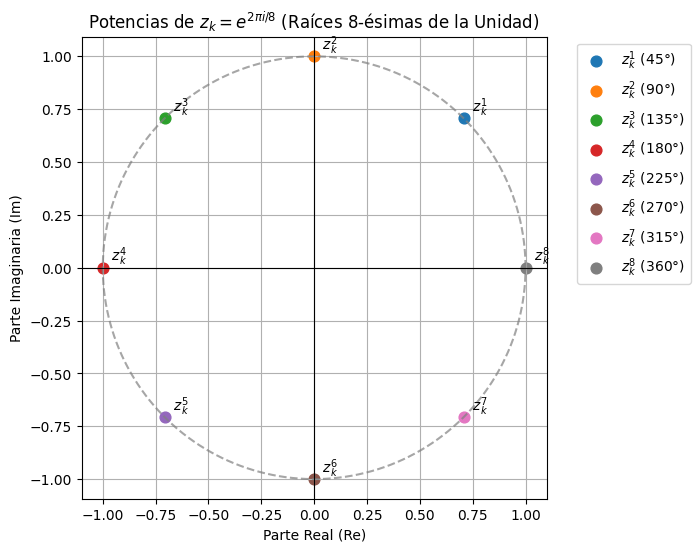

In [150]:
# Definición del número z_k = e^(2*pi*i / 8)
zk = np.exp(2j * np.pi / 8)

# Calculamos las potencias desde z_k^1 hasta z_k^8
potencias = [zk**k for k in range(1, 9)]

# Graficación de las potencias en el plano complejo
plt.figure(figsize=(6, 6))

# Dibujar circunferencia unitaria
t = np.linspace(0, 2 * np.pi, 200)
plt.plot(np.cos(t), np.sin(t), "gray", linestyle="--", alpha=0.7)

# Graficar cada potencia
for k, z_p in enumerate(potencias, 1):
    x_p, y_p = np.real(z_p), np.imag(z_p)
    plt.scatter(x_p, y_p, s=60, label=f"$z_k^{k}$ ({k*45}°)")
    plt.annotate(
        f"  $z_k^{k}$",
        (x_p, y_p),
        fontsize=10,
        verticalalignment="bottom",
    )

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.title(r"Potencias de $z_k = e^{2\pi i / 8}$ (Raíces 8-ésimas de la Unidad)")
plt.xlabel("Parte Real (Re)")
plt.ylabel("Parte Imaginaria (Im)")
plt.grid(True)
plt.axis("equal")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

## (b) i. Notación Bra-Ket para Producto Interno:
En mecánica cuántica, el producto interno de dos vectores ket $\vert{}u\rangle$ y $\vert{}v\rangle$ se escribe $\langle u \vert{} v \rangle$.   $\langle u\vert{}$ es el bra (vector fila traspuesto y conjugado de $\vert{}u\rangle$).   $\vert{}v\rangle$ es el ket (vector columna).
Por lo tanto, $\langle u \vert{} v \rangle = u^\dagger v$, donde $\dagger$ (daga) significa traspuesta conjugada.   ¿Qué es la Sesquilinealidad?"Sesqui" significa "uno y medio". Un producto interno sobre números complejos no es bilineal (lineal en ambos argumentos), sino sesquilineal:Es lineal en el segundo argumento ($\vert{}v\rangle$).Es antilineal (conjugado-lineal) en el primer argumento ($\langle u\vert{}$).Como consecuencia:$$\langle u \vert{} v \rangle = \langle v \vert{} u \rangle^*$$Es decir, invertir el orden nos da el conjugado complejo.¿Por qué np.dot NO funciona correctamente para esto?np.dot en NumPy realiza una multiplicación matricial estándar sin conjugar los elementos ($u^T v$). Ignora el hecho de que estamos en un espacio vectorial complejo.np.vdot aplica automáticamente la conjugación compleja al primer vector antes de realizar la multiplicación de puntos ($\bar{u}^T v$), cumpliendo con la definición cuántica exacta.




In [151]:
import numpy as np

# Definición de vectores u y v como vectores de C^3
u = np.array([1 + 1j, 2, -1j])
v = np.array([1j, 1 - 1j, 2])

# Cálculo correcto del producto interno usando np.vdot
u_v = np.vdot(u, v)  # <u|v>
v_u = np.vdot(v, u)  # <v|u>

# Intento incorrecto con np.dot
dot_incorrecto = np.dot(u, v)

print(" Resultados de Producto Interno:")
print(f"<u|v> con np.vdot: {u_v}")
print(f"<v|u> con np.vdot: {v_u}")
print(f"¿<u|v> es la conjugada de <v|u>?: {np.isclose(u_v, np.conj(v_u))}")
print(f"\nResultado incorrecto con np.dot(u, v): {dot_incorrecto}")

 Resultados de Producto Interno:
<u|v> con np.vdot: (3+1j)
<v|u> con np.vdot: (3-1j)
¿<u|v> es la conjugada de <v|u>?: True

Resultado incorrecto con np.dot(u, v): (1-3j)


ii: Operadores de Pauli y Hadamard mediante Productos Externos. Base computacional:$$\vert{}0\rangle = \begin{pmatrix} 1 \\ 0 \end{pmatrix}, \quad \vert{}1\rangle = \begin{pmatrix} 0 \\ 1 \end{pmatrix}$$Sus bras asociados son:$$\langle 0\vert{} = \begin{pmatrix} 1 & 0 \end{pmatrix}, \quad \langle 1\vert{} = \begin{pmatrix} 0 & 1 \end{pmatrix}$$Producto Externo ($\vert{}a\rangle\langle b\vert{}$):Es la multiplicación de un vector columna por un vector fila, generando una matriz $2 \times 2$:$$\vert{}0\rangle\langle 0\vert{} = \begin{pmatrix} 1 \\ 0 \end{pmatrix} \begin{pmatrix} 1 & 0 \end{pmatrix} = \begin{pmatrix} 1 & 0 \\ 0 & 0 \end{pmatrix}, \quad \vert{}0\rangle\langle 1\vert{} = \begin{pmatrix} 0 & 1 \\ 0 & 0 \end{pmatrix}$$$$\vert{}1\rangle\langle 0\vert{} = \begin{pmatrix} 0 & 0 \\ 1 & 0 \end{pmatrix}, \quad \vert{}1\rangle\langle 1\vert{} = \begin{pmatrix} 0 & 0 \\ 0 & 1 \end{pmatrix}$$Con estas 4 matrices elementales podemos construir cualquier operador de 1 qubit mediante suma.

In [152]:
# Definimos la base computacional como vectores columna de 2x1
ket0 = np.array([[1], [0]], dtype=complex)
ket1 = np.array([[0], [1]], dtype=complex)

# Productos externos elementales (|a><b|) usando np.outer
outer_00 = np.outer(ket0, np.conj(ket0))  # |0><0|
outer_01 = np.outer(ket0, np.conj(ket1))  # |0><1|
outer_10 = np.outer(ket1, np.conj(ket0))  # |1><0|
outer_11 = np.outer(ket1, np.conj(ket1))  # |1><1|

# A. Compuerta X = |0><1| + |1><0|
X = outer_01 + outer_10

# B. Compuerta Y = -i|0><1| + i|1><0|
Y = -1j * outer_01 + 1j * outer_10

# C. Compuerta H = (1/sqrt(2)) * (|0><0| + |0><1| + |1><0| - |1><1|)
H = (1 / np.sqrt(2)) * (outer_00 + outer_01 + outer_10 - outer_11)

print("Matriz X (Pauli-X):\n", X)
print("\nMatriz Y (Pauli-Y):\n", Y)
print("\nMatriz H (Hadamard):\n", np.round(H, 4))

# Verificación de acción sobre los estados de la base |0> y |1>
print("\n=== Acción de las compuertas ===")
print("X|0> (debe dar |1>):\n", np.dot(X, ket0))
print("H|0> (debe dar |+>):\n", np.round(np.dot(H, ket0), 4))

Matriz X (Pauli-X):
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

Matriz Y (Pauli-Y):
 [[0.+0.j 0.-1.j]
 [0.+1.j 0.+0.j]]

Matriz H (Hadamard):
 [[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

=== Acción de las compuertas ===
X|0> (debe dar |1>):
 [[0.+0.j]
 [1.+0.j]]
H|0> (debe dar |+>):
 [[0.7071+0.j]
 [0.7071+0.j]]


iii: Producto Tensorial.
El producto tensorial $\otimes$ se usa para combinar dos sistemas cuánticos independientes.   Para los estados:$$|+\rangle = \frac{1}{\sqrt{2}}|0\rangle + \frac{1}{\sqrt{2}}|1\rangle = \begin{pmatrix} \frac{1}{\sqrt{2}} \\ \frac{1}{\sqrt{2}} \end{pmatrix}$$$$|\psi\rangle = \frac{\sqrt{3}}{2}|0\rangle + \frac{i}{2}|1\rangle = \begin{pmatrix} \frac{\sqrt{3}}{2} \\ \frac{i}{2} \end{pmatrix}$$Desarrollo analítico del producto tensorial $|\Phi\rangle = |+\rangle \otimes |\psi\rangle$:$$|\Phi\rangle = \begin{pmatrix} \frac{1}{\sqrt{2}} \begin{pmatrix} \frac{\sqrt{3}}{2} \\ \frac{i}{2} \end{pmatrix} \\ \frac{1}{\sqrt{2}} \begin{pmatrix} \frac{\sqrt{3}}{2} \\ \frac{i}{2} \end{pmatrix} \end{pmatrix} = \begin{pmatrix} \frac{\sqrt{3}}{2\sqrt{2}} \\ \frac{i}{2\sqrt{2}} \\ \frac{\sqrt{3}}{2\sqrt{2}} \\ \frac{i}{2\sqrt{2}} \end{pmatrix} = \frac{\sqrt{3}}{2\sqrt{2}}|00\rangle + \frac{i}{2\sqrt{2}}|01\rangle + \frac{\sqrt{3}}{2\sqrt{2}}|10\rangle + \frac{i}{2\sqrt{2}}|11\rangle$$

In [153]:
# Definimos los estados individuales
ket_plus = (1 / np.sqrt(2)) * (ket0 + ket1)
ket_psi = (np.sqrt(3) / 2) * ket0 + (1j / 2) * ket1

# Estado compuesto |Phi> mediante np.kron
Phi = np.kron(ket_plus, ket_psi)

# Cálculo explícito de la forma analítica teórica
coef_00 = np.sqrt(3) / (2 * np.sqrt(2))
coef_01 = 1j / (2 * np.sqrt(2))
coef_10 = np.sqrt(3) / (2 * np.sqrt(2))
coef_11 = 1j / (2 * np.sqrt(2))

Phi_teorico = np.array([[coef_00], [coef_01], [coef_10], [coef_11]])

print("Estado |Phi> calculado con np.kron:\n", np.round(Phi, 4))
print("\n¿Coincide exactamente con la solución analítica?:", np.allclose(Phi, Phi_teorico))

Estado |Phi> calculado con np.kron:
 [[0.6124+0.j    ]
 [0.    +0.3536j]
 [0.6124+0.j    ]
 [0.    +0.3536j]]

¿Coincide exactamente con la solución analítica?: True


##(d) Construcción de la matriz

$A$:$$I =
\begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}, \quad X = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}, \quad Z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$$$$A = 2I + X + Z = \begin{pmatrix} 2 & 0 \\ 0 & 2 \end{pmatrix} + \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} + \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix} = \begin{pmatrix} 3 & 1 \\ 1 & 1 \end{pmatrix}$$Eigenvalores ($\lambda$) y Eigenvectores:
Se obtienen resolviendo el polinomio característico $\det(A - \lambda I) = 0$:
   $$\det \begin{pmatrix} 3-\lambda & 1 \\ 1 & 1-\lambda \end{pmatrix} = (3-\lambda)(1-\lambda) - 1 = \lambda^2 - 4\lambda + 2 = 0$$Aplicando la fórmula general:$$\lambda = \frac{4 \pm \sqrt{16 - 8}}{2} = 2 \pm \sqrt{2}$$
Así, tenemos $\lambda_{\min} = 2 - \sqrt{2} \approx 0.5858$ y $\lambda_{\max} = 2 + \sqrt{2} \approx 3.4142$.   Demostración de los Límites Espectrales ($\lambda_{\min} \le \langle \psi \vert{} A \vert{} \psi \rangle \le \lambda_{\max}$):   
Como $A$ es una matriz hermítica, por el Teorema Espectral se puede escribir en su base de autovectores $\{\vert{}v_1\rangle, \vert{}v_2\rangle\}$ con autovalores $\lambda_1, \lambda_2$. Para cualquier estado normalizado $\vert{}\psi\rangle = c_1 \vert{}v_1\rangle + c_2 \vert{}v_2\rangle$ (con $\vert{}c_1\vert{}^2 + \vert{}c_2\vert{}^2 = 1$):
   $$\langle \psi \vert{} A \vert{} \psi \rangle = \lambda_1 \vert{}c_1\vert{}^2 + \lambda_2 \vert{}c_2\vert{}^2$$Como $\vert{}c_1\vert{}^2 + \vert{}c_2\vert{}^2 = 1$, la combinación convexa de los autovalores está acotada estrictamente por el menor y el mayor de ellos:$$\lambda_{\min} \le \langle \psi \vert{} A \vert{} \psi \rangle \le \lambda_{\max}$$
  
**Demostración de Límites Espectrales:**
Para cualquier observable hermítico $A$ con eigenvalores $\lambda_{\min}$ y $\lambda_{\max}$ y cualquier estado normalizado $|\psi\rangle$, el valor esperado se expresa como:
$$\langle A \rangle = \langle \psi | A | \psi \rangle = \sum_i \lambda_i |c_i|^2$$
Como $\sum_i |c_i|^2 = 1$, la suma ponderada no puede ser menor que el menor eigenvalor ni mayor que el mayor:
$$\lambda_{\min} \le \langle \psi | A | \psi \rangle \le \lambda_{\max}$$

Matriz A:
 [[3. 1.]
 [1. 1.]]

Eigenvalores calculados: [0.58578644 3.41421356]
  lambda_min = 0.5858
  lambda_max = 3.4142


<>:37: SyntaxWarning: invalid escape sequence '\l'
<>:38: SyntaxWarning: invalid escape sequence '\l'
<>:37: SyntaxWarning: invalid escape sequence '\l'
<>:38: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_2888/945910901.py:37: SyntaxWarning: invalid escape sequence '\l'
  plt.axhline(lambda_min, color="red", linestyle="--", linewidth=1.5, label=f"$\lambda_{{min}} = {lambda_min:.4f}$")
/tmp/ipykernel_2888/945910901.py:38: SyntaxWarning: invalid escape sequence '\l'
  plt.axhline(lambda_max, color="green", linestyle="--", linewidth=1.5, label=f"$\lambda_{{max}} = {lambda_max:.4f}$")


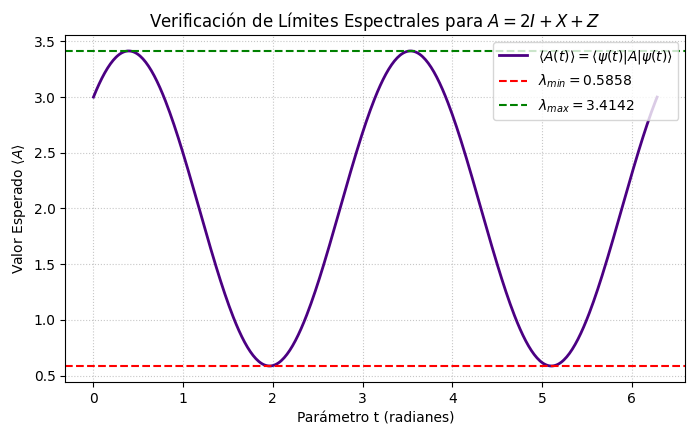

In [154]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Construcción de la matriz A = 2I + X + Z
I = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Z = np.array([[1, 0], [0, -1]])

A = 2 * I + X + Z

# 2. Eigenvalores y Eigenvectores
eigenvalores, eigenvectores = np.linalg.eigh(A)
lambda_min = np.min(eigenvalores)
lambda_max = np.max(eigenvalores)

print("Matriz A:\n", A)
print(f"\nEigenvalores calculados: {eigenvalores}")
print(f"  lambda_min = {lambda_min:.4f}")
print(f"  lambda_max = {lambda_max:.4f}")

# 3. Graficación de <A(t)> para t en [0, 2*pi]
t_vals = np.linspace(0, 2 * np.pi, 400)
valores_esperados = []

for t in t_vals:
    # Estado |psi(t)> = cos(t)|0> + sin(t)|1>
    psi_t = np.array([np.cos(t), np.sin(t)])
    # Valor esperado <A(t)> = <psi(t)|A|psi(t)>
    val_esp = np.vdot(psi_t, np.dot(A, psi_t))
    valores_esperados.append(np.real(val_esp))

# Graficación
plt.figure(figsize=(8, 4.5))
plt.plot(t_vals, valores_esperados, color="indigo", linewidth=2, label=r"$\langle A(t) \rangle = \langle \psi(t)|A|\psi(t) \rangle$")

# Líneas horizontales de los límites espectrales
plt.axhline(lambda_min, color="red", linestyle="--", linewidth=1.5, label=f"$\lambda_{{min}} = {lambda_min:.4f}$")
plt.axhline(lambda_max, color="green", linestyle="--", linewidth=1.5, label=f"$\lambda_{{max}} = {lambda_max:.4f}$")

plt.title(r"Verificación de Límites Espectrales para $A = 2I + X + Z$")
plt.xlabel("Parámetro t (radianes)")
plt.ylabel(r"Valor Esperado $\langle A \rangle$")
plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(loc="upper right")
plt.show()

## (e): Varianza de Observables y Diagonalización de Matrices de Pauli

#### 1. Definición de Varianza:
$$\text{Var}(A) = \langle A^2 \rangle - \langle A \rangle^2$$

#### 2. Deducción de $\text{Var}(A) = 1 - \langle A \rangle^2$ para matrices de Pauli:
Para las matrices de Pauli ($X, Y, Z$), se cumple que $X^2 = Y^2 = Z^2 = I$.
Para cualquier estado normalizado $|\psi\rangle$:
$$\langle A^2 \rangle = \langle \psi | I | \psi \rangle = 1$$
Sustituyendo en la fórmula de la varianza:
$$\text{Var}(A) = 1 - \langle A \rangle^2$$

=== Diagonalización y Reconstrucción por Descomposición Espectral ===

Matriz Pauli-X:
  Eigenvalores: [-1.  1.]
  ¿Reconstrucción correcta?: True

Matriz Pauli-Y:
  Eigenvalores: [-1.  1.]
  ¿Reconstrucción correcta?: True

Matriz Pauli-Z:
  Eigenvalores: [-1.  1.]
  ¿Reconstrucción correcta?: True

=== Verificación de Var(A) = 1 - <A>^2 ===

Estado |0⟩:
  Observable X: <X> = 0.00 | Var Directa = 1.0000 | 1 - <X>^2 = 1.0000
  Observable Y: <Y> = 0.00 | Var Directa = 1.0000 | 1 - <Y>^2 = 1.0000
  Observable Z: <Z> = 1.00 | Var Directa = 0.0000 | 1 - <Z>^2 = 0.0000

Estado |+⟩:
  Observable X: <X> = 1.00 | Var Directa = 0.0000 | 1 - <X>^2 = 0.0000
  Observable Y: <Y> = 0.00 | Var Directa = 1.0000 | 1 - <Y>^2 = 1.0000
  Observable Z: <Z> = 0.00 | Var Directa = 1.0000 | 1 - <Z>^2 = 1.0000

Estado |ψ_i⟩:
  Observable X: <X> = 0.00 | Var Directa = 1.0000 | 1 - <X>^2 = 1.0000
  Observable Y: <Y> = 1.00 | Var Directa = 0.0000 | 1 - <Y>^2 = 0.0000
  Observable Z: <Z> = 0.00 | Var Directa = 1.0

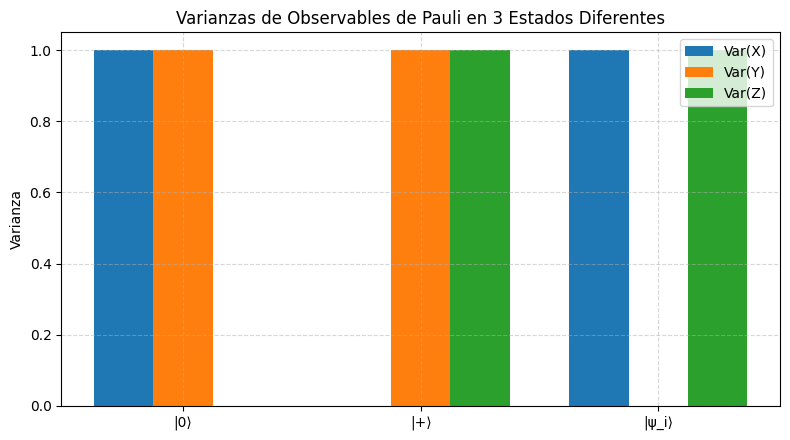

In [155]:
import numpy as np
import matplotlib.pyplot as plt

# Definición de las matrices de Pauli
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

matrices_pauli = {'X': X, 'Y': Y, 'Z': Z}

print("=== Diagonalización y Reconstrucción por Descomposición Espectral ===")
for nombre, M in matrices_pauli.items():
    vals, vecs = np.linalg.eigh(M)

    # Reconstrucción M = sum(lambda_i * |v_i><v_i|)
    M_reconstruida = np.zeros((2, 2), dtype=complex)
    for i in range(2):
        v_i = vecs[:, i].reshape(2, 1)  # Autovector ket
        proj = np.dot(v_i, np.conj(v_i).T)  # Producto exterior |v_i><v_i|
        M_reconstruida += vals[i] * proj

    print(f"\nMatriz Pauli-{nombre}:")
    print(f"  Eigenvalores: {vals}")
    print(f"  ¿Reconstrucción correcta?: {np.allclose(M, M_reconstruida)}")

# --- Verificación de la Varianza para 3 Estados Distintos ---
# 1. Estado |0>
psi1 = np.array([1, 0], dtype=complex)
# 2. Estado |+> = (|0> + |1>)/sqrt(2)
psi2 = (1 / np.sqrt(2)) * np.array([1, 1], dtype=complex)
# 3. Estado arbitrario (|0> + i|1>)/sqrt(2)
psi3 = (1 / np.sqrt(2)) * np.array([1, 1j], dtype=complex)

estados = [("|0⟩", psi1), ("|+⟩", psi2), ("|ψ_i⟩", psi3)]

print("\n=== Verificación de Var(A) = 1 - <A>^2 ===")
varianzas_dict = {nombre: [] for nombre in matrices_pauli.keys()}

for nombre_est, psi in estados:
    print(f"\nEstado {nombre_est}:")
    for nombre_m, M in matrices_pauli.items():
        # Valor esperado <A>
        val_esp = np.real(np.vdot(psi, np.dot(M, psi)))

        # Varianza directa <A^2> - <A>^2
        M2 = np.dot(M, M)
        val_esp_2 = np.real(np.vdot(psi, np.dot(M2, psi)))
        var_directa = val_esp_2 - (val_esp**2)

        # Varianza por fórmula simplificada 1 - <A>^2
        var_formula = 1 - (val_esp**2)

        varianzas_dict[nombre_m].append(var_directa)

        print(f"  Observable {nombre_m}: <{nombre_m}> = {val_esp:.2f} | Var Directa = {var_directa:.4f} | 1 - <{nombre_m}>^2 = {var_formula:.4f}")

# Graficación de las varianzas obtenidas
fig, ax = plt.subplots(figsize=(8, 4.5))
x_indices = np.arange(len(estados))
ancho_barra = 0.25

for i, (nombre_m, vars_lista) in enumerate(varianzas_dict.items()):
    ax.bar(x_indices + i * ancho_barra, vars_lista, width=ancho_barra, label=f"Var({nombre_m})")

ax.set_xticks(x_indices + ancho_barra)
ax.set_xticklabels([est[0] for est in estados])
ax.set_ylabel("Varianza")
ax.set_title("Varianzas de Observables de Pauli en 3 Estados Diferentes")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

# 4. Qiskit

##(a). Prepararemos el estado $|\psi\rangle = \frac{\sqrt{3}}{2}|0\rangle + \frac{1}{2}|1\rangle$ mediante $R_y(\theta)$

### Cálculo Analítico del Ángulo
Para preparar el estado $|\psi\rangle$ aplicando $R_y(\theta)$ al estado inicial $|0\rangle$:
$$R_y(\theta)|0\rangle = \cos\left(\frac{\theta}{2}\right)|0\rangle + \sin\left(\frac{\theta}{2}\right)|1\rangle$$

Igualando componentes con $|\psi\rangle = \frac{\sqrt{3}}{2}|0\rangle + \frac{1}{2}|1\rangle$:
$$\cos\left(\frac{\theta}{2}\right) = \frac{\sqrt{3}}{2} \implies \frac{\theta}{2} = \frac{\pi}{6} \implies \theta = \frac{\pi}{3}$$

Las probabilidades teóricas (cuadrado de las amplitudes) son:
- $P(0) = \left(\frac{\sqrt{3}}{2}\right)^2 = 0.75$ ($75\%$)
- $P(1) = \left(\frac{1}{2}\right)^2 = 0.25$ ($25\%$)

Vector de Estado Obtenido
Statevector([0.8660254+0.j, 0.5      +0.j],
            dims=(2,))

=== Comparación de Frecuencias vs Amplitudes al Cuadrado ===
Teórico  -> P(0): 0.7500 | P(1): 0.2500
Simulado -> P(0): 0.7524 | P(1): 0.2476


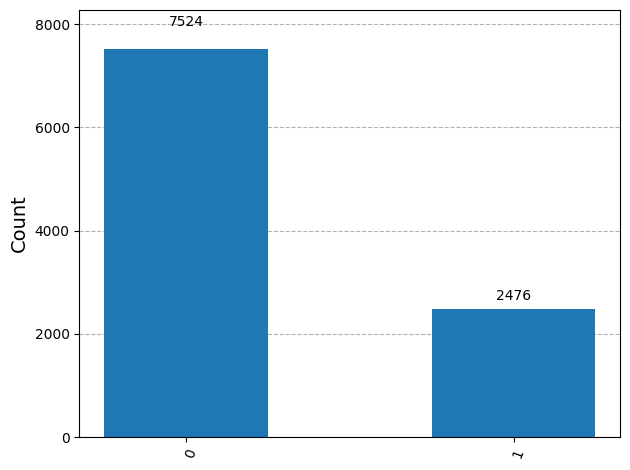

In [156]:
#1. Instalamos lo que vimos en el lab antes de utilizar qiskit
!pip install qiskit
!pip install pylatexenc
!pip install qiskit-aer

# 2. Importaciones de Qiskit y bibliotecas auxiliares
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# 3. Cálculo del ángulo theta = pi / 3
theta = np.pi / 3

# 4. Creación del circuito cuántico de 1 qubit
qc = QuantumCircuit(1)
qc.ry(theta, 0)

# 5. Obtención y verificación del Statevector
estado = Statevector.from_instruction(qc)
print("Vector de Estado Obtenido")
print(estado)

# 6. Simulación con mediciones (10,000 shots)
qc_medido = qc.copy()
qc_medido.measure_all()

simulador = AerSimulator()
job = simulador.run(qc_medido, shots=10000)
resultados = job.result().get_counts()

# Cálculo de probabilidades/frecuencias
frec_0 = resultados.get("0", 0) / 10000
frec_1 = resultados.get("1", 0) / 10000

print("\n=== Comparación de Frecuencias vs Amplitudes al Cuadrado ===")
print(f"Teórico  -> P(0): 0.7500 | P(1): 0.2500")
print(f"Simulado -> P(0): {frec_0:.4f} | P(1): {frec_1:.4f}")

# Muestra del histograma
plot_histogram(resultados)

##(b). Circuitos $H \rightarrow S$ y $S \rightarrow H$, Operadores y Mediciones en Bases Z y X

 Análisis Teórico
1. Circuito 1 ($H$ luego $S$): $S \cdot H |0\rangle = \frac{|0\rangle + i|1\rangle}{\sqrt{2}}$.
2. Circuito 2 ($S$ luego $H$): $H \cdot S |0\rangle = H |0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$.

Las matrices no conmutan ($SH \neq HS$), por lo que los operadores globales y los estados finales son distintos.

In [157]:
from qiskit.quantum_info import Operator

# Circuito 1: Aplica H y luego S
qc1 = QuantumCircuit(1)
qc1.h(0)
qc1.s(0)

#  Circuito 2: Aplica S y luego H
qc2 = QuantumCircuit(1)
qc2.s(0)
qc2.h(0)

# Operadores matriciales y Statevectors
op1, op2 = Operator(qc1), Operator(qc2)
sv1, sv2 = Statevector.from_instruction(qc1), Statevector.from_instruction(qc2)

print("Matriz Operador 1 (H -> S):\n", op1.data)
print("\nMatriz Operador 2 (S -> H):\n", op2.data)
print("\nStatevector 1:", sv1.data)
print("Statevector 2:", sv2.data)

# MEDICIONES EN BASE Z
qc1_z = qc1.copy()
qc1_z.measure_all()
qc2_z = qc2.copy()
qc2_z.measure_all()

counts1_z = simulador.run(qc1_z, shots=5000).result().get_counts()
counts2_z = simulador.run(qc2_z, shots=5000).result().get_counts()

# MEDICIONES EN BASE X (Aplicando H antes de medir)
qc1_x = qc1.copy()
qc1_x.h(0)  # Rotación a base X
qc1_x.measure_all()

qc2_x = qc2.copy()
qc2_x.h(0)  # Rotación a base X
qc2_x.measure_all()

counts1_x = simulador.run(qc1_x, shots=5000).result().get_counts()
counts2_x = simulador.run(qc2_x, shots=5000).result().get_counts()

print("\n Resultados de Mediciones:")
print("Circuito 1 en Base Z:", counts1_z)
print("Circuito 2 en Base Z:", counts2_z)
print("Circuito 1 en Base X:", counts1_x)
print("Circuito 2 en Base X:", counts2_x)

Matriz Operador 1 (H -> S):
 [[0.70710678+0.j         0.70710678+0.j        ]
 [0.        +0.70710678j 0.        -0.70710678j]]

Matriz Operador 2 (S -> H):
 [[0.70710678+0.j         0.        +0.70710678j]
 [0.70710678+0.j         0.        -0.70710678j]]

Statevector 1: [0.70710678+0.j         0.        +0.70710678j]
Statevector 2: [0.70710678+0.j 0.70710678+0.j]

 Resultados de Mediciones:
Circuito 1 en Base Z: {'0': 2421, '1': 2579}
Circuito 2 en Base Z: {'1': 2453, '0': 2547}
Circuito 1 en Base X: {'0': 2463, '1': 2537}
Circuito 2 en Base X: {'0': 5000}


##(c). 2 circuitos de 2 qubits, uno con una compuerta SWAP y otro mediante 3 CNOTs

Demostramos que el operador generado por una compuerta SWAP directa coincide con el operador generado por la secuencia de 3 CNOTs: $CNOT_{0,1} \rightarrow CNOT_{1,0} \rightarrow CNOT_{0,1}$.

In [158]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Statevector

# 1. Circuito con SWAP
qc_swap = QuantumCircuit(2)
qc_swap.swap(0, 1)

# 2. Circuito con 3 CNOTs
qc_cnots = QuantumCircuit(2)
qc_cnots.cx(0, 1)
qc_cnots.cx(1, 0)
qc_cnots.cx(0, 1)

# Comparación de operadores matriciales
op_swap = Operator(qc_swap)
op_cnots = Operator(qc_cnots)

print("¿Los operadores matriciales son equivalentes?:", op_swap == op_cnots)

# 3. Verificación con un estado aleatorio de 2 qubits
reales = np.random.uniform(-1, 1, size=4)
imaginarios = np.random.uniform(-1, 1, size=4)
vector_complejo = reales + 1j * imaginarios

# Normalizamos el vector para que sea un estado cuántico válido
vector_complejo /= np.linalg.norm(vector_complejo)

# Creamos el Statevector
estado_aleatorio = Statevector(vector_complejo)

# Evolucionamos el estado en ambos circuitos
res_swap = estado_aleatorio.evolve(qc_swap)
res_cnots = estado_aleatorio.evolve(qc_cnots)

print(
    "¿Evolucionan el estado aleatorio al mismo resultado?:",
    res_swap == res_cnots,
)

¿Los operadores matriciales son equivalentes?: True
¿Evolucionan el estado aleatorio al mismo resultado?: True


##(d). Los Estados de Bell son la base ortonormal de estados máximamente entrelazados de 2 qubits[5]:
   $\vert{}\Phi^+\rangle = \frac{\vert{}00\rangle + \vert{}11\rangle}{\sqrt{2}}$$\vert{}\Phi^-\rangle = \frac{\vert{}00\rangle - \vert{}11\rangle}{\sqrt{2}}$$\vert{}\Psi^+\rangle = \frac{\vert{}01\rangle + \vert{}10\rangle}{\sqrt{2}}$$\vert{}\Psi^-\rangle = \frac{\vert{}01\rangle - \vert{}10\rangle}{\sqrt{2}}$

   Construimos los 4 estados entrelazados de Bell utilizando combinaciones de compuertas $H$, $X$, $Z$ y $CNOT$.

In [159]:
# Función para crear cada estado de Bell
def crear_bell(tipo):
    qc = QuantumCircuit(2)
    if tipo == "Phi+":
        qc.h(0)
        qc.cx(0, 1)
    elif tipo == "Phi-":
        qc.x(0)
        qc.h(0)
        qc.cx(0, 1)
    elif tipo == "Psi+":
        qc.x(1)
        qc.h(0)
        qc.cx(0, 1)
    elif tipo == "Psi-":
        qc.x(1)
        qc.z(0)
        qc.h(0)
        qc.cx(0, 1)
    return qc


estados = ["Phi+", "Phi-", "Psi+", "Psi-"]

for est in estados:
    qc_b = crear_bell(est)
    sv = Statevector.from_instruction(qc_b)
    print(f"--- Estado de Bell |{est}> ---")
    print("Vector de estado:", np.round(sv.data, 3))

--- Estado de Bell |Phi+> ---
Vector de estado: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]
--- Estado de Bell |Phi-> ---
Vector de estado: [ 0.707+0.j  0.   +0.j  0.   +0.j -0.707+0.j]
--- Estado de Bell |Psi+> ---
Vector de estado: [0.   +0.j 0.707+0.j 0.707+0.j 0.   +0.j]
--- Estado de Bell |Psi-> ---
Vector de estado: [0.   +0.j 0.707+0.j 0.707+0.j 0.   +0.j]


##(e). Circuito Unitario $U$, su Inverso $U^{-1}$ e Identidad
Diseñamos un circuito unitario $U$ de 2 qubits con al menos 5 compuertas (incluyendo un CNOT y rotaciones)[cite: 5]. Recuperamos su inverso $U^{-1}$ con .inverse() y comprobamos que la composición $U^{-1} U = I$.

In [160]:
# 1. Diseñamos el circuito unitario U con 5 compuertas
U = QuantumCircuit(2, name="U")
U.h(0)
U.ry(np.pi / 4, 1)
U.cx(0, 1)
U.rz(np.pi / 3, 0)
U.x(1)

# 2. Inverso de U
U_inv = U.inverse()

# 3. Circuito compuesto U_total = U seguido de U_inv
U_total = QuantumCircuit(2)
U_total.compose(U, inplace=True)
U_total.compose(U_inv, inplace=True)

# 4. Obtención de matriz de la composición
op_total = Operator(U_total)

print("=== Matriz del Circuito Compuesto U_inv * U ===")
print(np.round(op_total.data, 4))
print(
    "\n¿Es exactamente igual a la matriz Identidad?:",
    np.allclose(op_total.data, np.eye(4)),
)

=== Matriz del Circuito Compuesto U_inv * U ===
[[ 1.+0.j  0.-0.j  0.+0.j  0.-0.j]
 [ 0.-0.j  1.+0.j  0.-0.j  0.+0.j]
 [-0.+0.j  0.+0.j  1.+0.j  0.-0.j]
 [ 0.+0.j -0.+0.j  0.-0.j  1.+0.j]]

¿Es exactamente igual a la matriz Identidad?: True


##(f). Preparación de $\vert{}\psi\rangle$, Compuerta $U = X \otimes H$ y Verificación Matricial

Representamos el estado $\vert{}\psi\rangle = \frac{1}{\sqrt{7}}(\vert{}00\rangle + i\vert{}01\rangle + 2\vert{}10\rangle - \vert{}11\rangle)$ en forma vectorial y aplicamos el operador $U = X \otimes H$ mediante UnitaryGate en Qiskit y multiplicación matricial en NumPy para comprobar que ambos resultados coinciden.

In [161]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

# 1. Definición del vector de estado |psi>
coef = 1 / np.sqrt(7)
psi_vec = coef * np.array([1, 1j, 2, -1], dtype=complex)

# 2. Definición de la matriz U = X (tensor) H en NumPy
X_mat = np.array([[0, 1], [1, 0]], dtype=complex)
H_mat = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)
U_mat = np.kron(X_mat, H_mat)

# 3. Multiplicación matricial independiente en NumPy
psi_final_numpy = np.dot(U_mat, psi_vec)

# 4. Implementación en Qiskit
qc = QuantumCircuit(2)
qc.initialize(psi_vec, [0, 1])  # Carga el estado inicial

gate_U = UnitaryGate(U_mat, label="X_tensor_H")
qc.append(gate_U, [0, 1])  # Aplica la compuerta U al circuito

# Recuperamos el estado final con Statevector
psi_final_qiskit = Statevector.from_instruction(qc).data

print("Comparación del Estado Final")
print("NumPy:  ", np.round(psi_final_numpy, 4))
print("Qiskit: ", np.round(psi_final_qiskit, 4))
print(
    "¿Coinciden exactamente?:",
    np.allclose(psi_final_numpy, psi_final_qiskit),
)

# 5. Mediciones y comparación con probabilidades teóricas
probabilidades_teoricas = np.abs(psi_final_numpy) ** 2

qc_med = qc.copy()
qc_med.measure_all()
sim = AerSimulator()
counts = sim.run(qc_med, shots=10000).result().get_counts()

print("\nProbabilidades Teóricas vs Frecuencias de Medición")
base_labels = ["00", "01", "10", "11"]
for idx, label in enumerate(base_labels):
    prob_p = probabilidades_teoricas[idx]
    frec_p = counts.get(label, 0) / 10000
    print(
        f"Estado |{label}⟩ -> Teoría: {prob_p:.4f} | Medido: {frec_p:.4f}"
    )

Comparación del Estado Final
NumPy:   [0.2673+0.j     0.8018+0.j     0.2673+0.2673j 0.2673-0.2673j]
Qiskit:  [0.2673+0.j     0.8018+0.j     0.2673+0.2673j 0.2673-0.2673j]
¿Coinciden exactamente?: True

Probabilidades Teóricas vs Frecuencias de Medición
Estado |00⟩ -> Teoría: 0.0714 | Medido: 0.0712
Estado |01⟩ -> Teoría: 0.6429 | Medido: 0.6414
Estado |10⟩ -> Teoría: 0.1429 | Medido: 0.1439
Estado |11⟩ -> Teoría: 0.1429 | Medido: 0.1435


##(g). Teorema de Descomposición Espectral:Todo operador hermítico $O$ se puede descomponer a partir de sus autovalores $\lambda_i$ y sus autovectores $\vert{}v_i\rangle$: $O = \sum_i \lambda_i \vert{}v_i\rangle\langle v_i\vert{}$.

Valores esperados para $\vert{}\psi\rangle = \alpha\vert{}0\rangle + \beta\vert{}1\rangle$ (donde $\vert{}\alpha\vert{}^2 + \vert{}\beta\vert{}^2 = 1$):

$\langle Z \rangle = \langle\psi\vert{}
Z\vert{}\psi\rangle = \vert{}\alpha\vert{}^2 - \vert{}\beta\vert{}^2$.

$\langle X \rangle = \langle\psi\vert{}X\vert{}\psi\rangle = \alpha^* \beta + \beta^* \alpha = 2 \text{Re}(\alpha^* \beta)$.

$\langle Y \rangle = \langle\psi\vert{}Y\vert{}\psi\rangle = -i \alpha^* \beta + i \beta^* \alpha = 2 \text{Im}(\alpha^* \beta)$.

Cómo medir $\langle X \rangle$ y $\langle Y \rangle$ en Qiskit:Para medir en la base de $Z$: medimos directamente la base computacional.Para medir en la base de $X$: aplicamos una compuerta $H$ antes de medir.Para medir en la base de $Y$: aplicamos $S^\dagger$ (o $R_z(-\pi/2)$) seguido de $H$ antes de medir.El valor esperado simulado es: $\langle O \rangle = \frac{\text{Conteo}(0) - \text{Conteo}(1)}{\text{Total de Shots}}$

(g). Valores Esperados $\langle Z \rangle, \langle X \rangle, \langle Y \rangle$ y Descomposición Espectral

 Demostración Matemática:
Para un estado normado $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$:
- $\langle Z \rangle = \begin{pmatrix} \alpha^* & \beta^* \end{pmatrix} \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix} \begin{pmatrix} \alpha \\ \beta \end{pmatrix} = |\alpha|^2 - |\beta|^2$
- $\langle X \rangle = \begin{pmatrix} \alpha^* & \beta^* \end{pmatrix} \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} \alpha \\ \beta \end{pmatrix} = \alpha^*\beta + \beta^*\alpha = 2\text{Re}(\alpha^*\beta)$
- $\langle Y \rangle = \begin{pmatrix} \alpha^* & \beta^* \end{pmatrix} \begin{pmatrix} 0 & -i \\ i & 0 \end{pmatrix} \begin{pmatrix} \alpha \\ \beta \end{pmatrix} = -i\alpha^*\beta + i\beta^*\alpha = 2\text{Im}(\alpha^*\beta)$

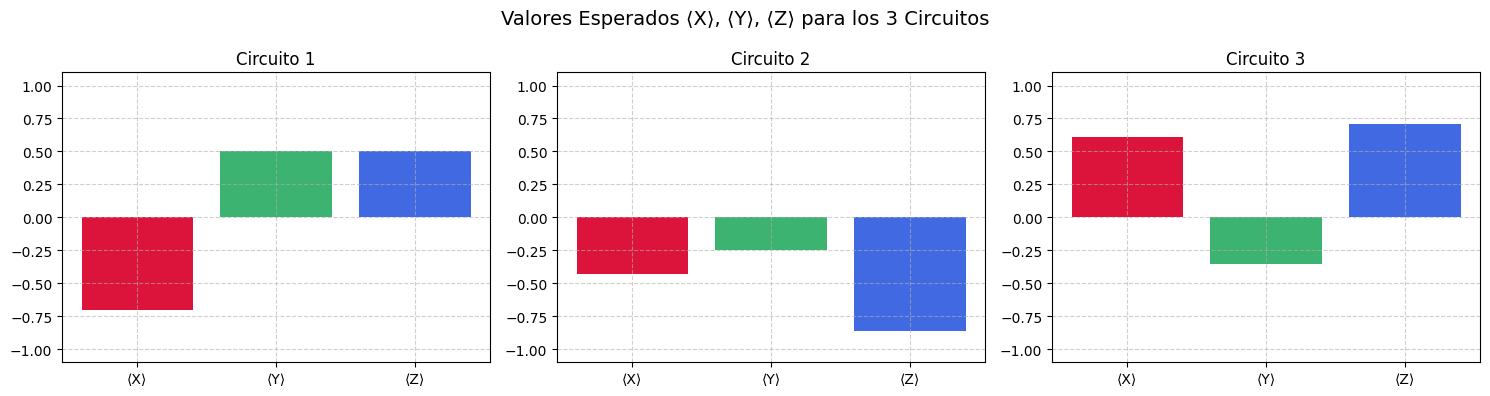

In [162]:
import matplotlib.pyplot as plt

# Diseñamos 3 circuitos distintos de al menos 4 compuertas cada uno
circuito1 = QuantumCircuit(1)  # Circuito 1
circuito1.h(0)
circuito1.t(0)
circuito1.s(0)
circuito1.rx(np.pi / 4, 0)

circuito2 = QuantumCircuit(1)  # Circuito 2
circuito2.x(0)
circuito2.ry(np.pi / 3, 0)
circuito2.h(0)
circuito2.rz(np.pi / 6, 0)

circuito3 = QuantumCircuit(1)  # Circuito 3
circuito3.ry(np.pi / 2, 0)
circuito3.rz(np.pi / 4, 0)
circuito3.rx(np.pi / 3, 0)
circuito3.h(0)

circuitos = [circuito1, circuito2, circuito3]


def calcular_valores_esperados_teoricos(qc):
    sv = Statevector.from_instruction(qc).data
    alpha, beta = sv[0], sv[1]
    exp_z = np.abs(alpha) ** 2 - np.abs(beta) ** 2
    exp_x = 2 * np.real(np.conj(alpha) * beta)
    exp_y = 2 * np.imag(np.conj(alpha) * beta)
    return exp_x, exp_y, exp_z


# Graficación de resultados
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

for i, qc in enumerate(circuitos):
    ex, ey, ez = calcular_valores_esperados_teoricos(qc)
    axs[i].bar(
        ["⟨X⟩", "⟨Y⟩", "⟨Z⟩"],
        [ex, ey, ez],
        color=["crimson", "mediumseagreen", "royalblue"],
    )
    axs[i].set_ylim(-1.1, 1.1)
    axs[i].set_title(f"Circuito {i+1}")
    axs[i].grid(True, linestyle="--", alpha=0.6)

plt.suptitle(
    "Valores Esperados ⟨X⟩, ⟨Y⟩, ⟨Z⟩ para los 3 Circuitos", fontsize=14
)
plt.tight_layout()
plt.show()

##(h). Creamos 2 circuitos cuánticos que fabriquen los estados
 $\vert{}GHZ\rangle$ y $\vert{}\Phi\rangle = \vert{}+\rangle\otimes\vert{}+\rangle\otimes\vert{}+\rangle$, Mediciones en Base Computacional y Diagonal1. Explicación teórica paso a paso:Estado GHZ (Greenberger-Horne-Zeilinger):Es un estado entrelazado de 3 qubits:$$\vert{}GHZ\rangle = \frac{\vert{}000\rangle + \vert{}111\rangle}{\sqrt{2}}$$Se construye aplicando $H$ al primer qubit y dos CNOTs consecutivos: $CNOT(0 \to 1)$ y $CNOT(1 \to 2)$.Estado $\vert{}\Phi\rangle = \vert{}+\rangle \otimes \vert{}+\rangle \otimes \vert{}+\rangle$:

Es un estado separable donde se aplica $H$ a cada uno de los 3 qubits por separado.Mediciones:Base Computacional (Base Z): Medición directa.Base Diagonal (Base X): Aplicamos una compuerta $H$ a todos los qubits antes de medir.

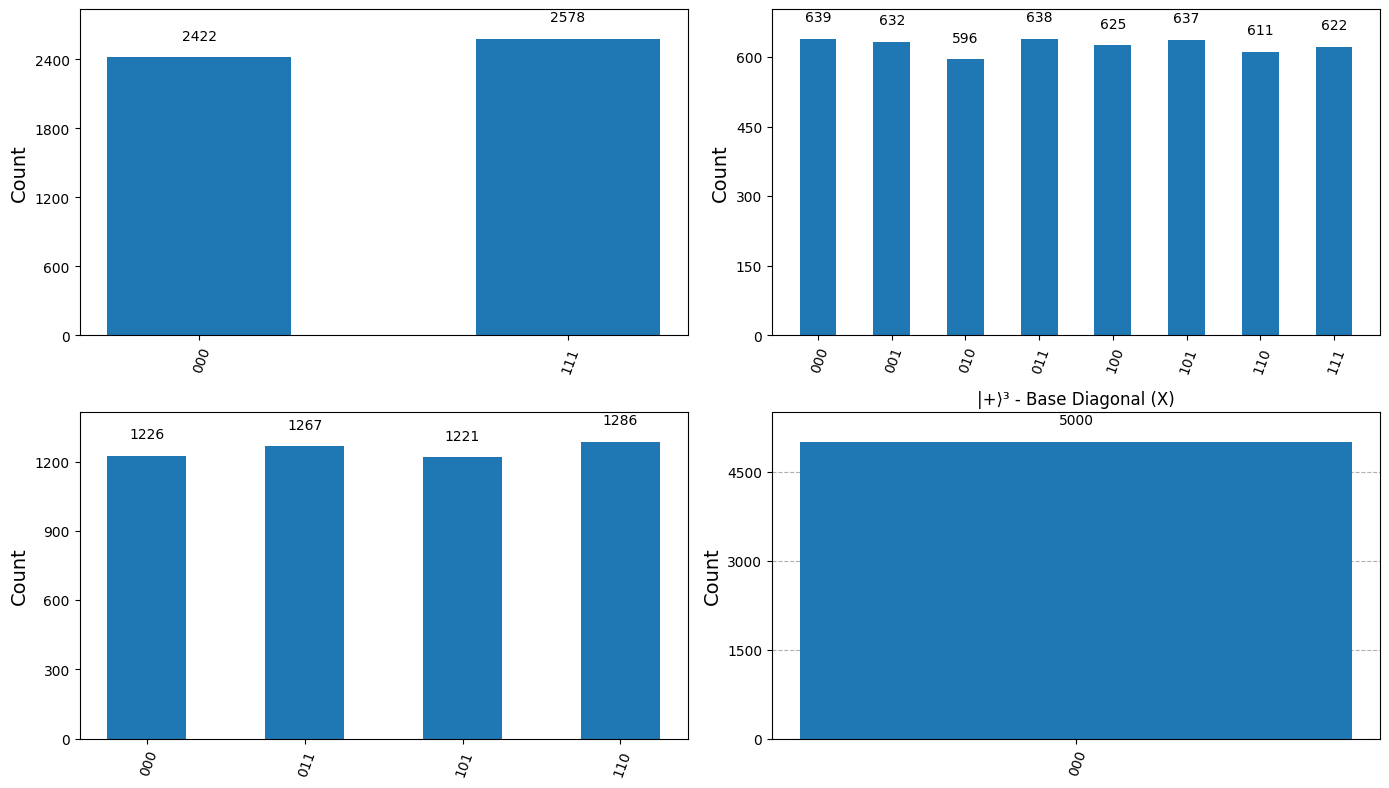

In [163]:
# 1. Circuito GHZ: (|000> + |111>) / sqrt(2)
qc_ghz = QuantumCircuit(3)
qc_ghz.h(0)
qc_ghz.cx(0, 1)
qc_ghz.cx(1, 2)

# 2. Circuito Phi: |+> ⊗ |+> ⊗ |+>
qc_phi = QuantumCircuit(3)
qc_phi.h(0)
qc_phi.h(1)
qc_phi.h(2)

# --- MEDICIONES EN BASE COMPUTACIONAL (BASE Z) ---
qc_ghz_z = qc_ghz.copy()
qc_ghz_z.measure_all()
qc_phi_z = qc_phi.copy()
qc_phi_z.measure_all()

counts_ghz_z = sim.run(qc_ghz_z, shots=5000).result().get_counts()
counts_phi_z = sim.run(qc_phi_z, shots=5000).result().get_counts()

# --- MEDICIONES EN BASE DIAGONAL (BASE X - Aplicando H a todos) ---
qc_ghz_x = qc_ghz.copy()
qc_ghz_x.h([0, 1, 2])
qc_ghz_x.measure_all()

qc_phi_x = qc_phi.copy()
qc_phi_x.h([0, 1, 2])
qc_phi_x.measure_all()

counts_ghz_x = sim.run(qc_ghz_x, shots=5000).result().get_counts()
counts_phi_x = sim.run(qc_phi_x, shots=5000).result().get_counts()

# Visualización con Histogramas
fig, ax = plt.subplots(2, 2, figsize=(14, 8))

plot_histogram(counts_ghz_z, ax=ax[0, 0], title="GHZ - Base Computacional (Z)")
plot_histogram(counts_phi_z, ax=ax[0, 1], title="|+⟩³ - Base Computacional (Z)")
plot_histogram(counts_ghz_x, ax=ax[1, 0], title="GHZ - Base Diagonal (X)")
plot_histogram(counts_phi_x, ax=ax[1, 1], title="|+⟩³ - Base Diagonal (X)")

plt.tight_layout()
plt.show()

# 5. Preguntas

### (a) La intuición de Richard Feynman y la lógica en el desarrollo del área

**Intuición de Feynman:**
En su famosa conferencia de 1981, Richard Feynman observó que simular la física y los sistemas cuánticos de la naturaleza utilizando computadoras clásicas convencionales es sumamente ineficiente y computacionalmente intratable debido al crecimiento exponencial de los estados cuánticos. Su intuición fue directa: si se quiere hacer una simulación precisa de la naturaleza física (que es intrínsecamente cuántica), el hardware de la propia máquina computadora debe operar bajo las leyes de la mecánica cuántica.

**¿Hemos seguido su lógica?**
Sí y no. Por un lado, sí hemos seguido su lógica al construir hardware basado en bits cuánticos (cúbits) que aprovechan la superposición y el entrelazamiento para resolver problemas físicos, químicos y de simulación de materiales que antes eran imposibles. Sin embargo, el área se ha ramificado enormemente hacia aplicaciones que Feynman no visualizó explícitamente en su propuesta inicial de simulación física, tales como la criptografía cuántica, algoritmos de optimización combinatoria y finanzas cuánticas.

### (b) La Interpretación de Copenhague y su conexión con el curso

**Explicación de la interpretación:**
Formulada principalmente por Niels Bohr y Werner Heisenberg, esta postura clásica de la mecánica cuántica sostiene que los sistemas físicos no poseen propiedades definidas antes de ser medidos. En su lugar, se describen mediante una función de onda que representa una distribución de probabilidad de estados. En el momento en que se realiza una medición, la función de onda sufre un "colapso" instantáneo a uno de los estados propios permitidos por el operador de medición.

**Observaciones y conexión con el curso:**
Una observación crítica es que esta interpretación introduce la indeterminación y el papel activo del observador como pilares fundamentales de la realidad física, lo cual rompe con el determinismo clásico.

Esto se conecta directamente con los fundamentos de programación y matemáticas que hemos desarrollado en la práctica:
1. Al estudiar distribuciones probabilísticas (como la normal 2D generada con `np.random.normal`), modelamos matemáticamente la incertidumbre antes de una observación de eventos concretos.
2. En computación cuántica, un cúbit en estado de superposición $\alpha|0\rangle + \beta|1\rangle$ no está definido como un bit clásico hasta que una medición lo obliga a colapsar de manera aleatoria a $0$ o $1$, con probabilidades dadas por $|\alpha|^2$ y $|\beta|^2$ respectivamente.

### (c) La Fase Global y su naturaleza en los estados cuánticos

**¿Qué es una fase global?**
Matemáticamente, si tenemos un estado cuántico representado por el vector de estado $|\psi\rangle$, multiplicar todo el estado por un factor de fase de la forma $e^{i\theta}$ (donde $\theta \in \mathbb{R}$) produce un nuevo estado $|\psi'\rangle = e^{i\theta}|\psi\rangle$. Este factor multiplicativo común se conoce como fase global.

**¿Por qué no altera la naturaleza física?**
Toda predicción física medible en mecánica cuántica depende de calcular valores esperados de operadores observables $A$ o probabilidades a través del módulo al cuadrado. Para cualquier estado $|\psi'\rangle$:
$$\langle\psi'| A |\psi'\rangle = \left(\langle\psi| e^{-i\theta}\right) A \left(e^{i\theta}|\psi\rangle\right) = e^{-i\theta} e^{i\theta} \langle\psi| A |\psi\rangle = \langle\psi| A |\psi\rangle$$
Como los operadores de fase global se cancelan mutuamente con sus conjugados hermíticos en cualquier medición o proyección física, el estado resultante es físicamente idéntico e indistinguible del original.

**Ejemplos:**
1. En un solo qubit, el estado $|0\rangle$ y el estado $-|0\rangle$ (donde $e^{i\pi} = -1$) son físicamente idénticos.
2. El estado de superposición $|+\rangle = \frac{1}{\sqrt{2}}(|0\rangle + |1\rangle)$ y el estado $i|+\rangle = \frac{i}{\sqrt{2}}(|0\rangle + |1\rangle)$ (donde $e^{i\pi/2} = i$) representan exactamente el mismo estado físico tras la medición.

**¿Por qué existe si no altera nada?**
La fase global es una consecuencia inevitable de la estructura matemática del espacio de Hilbert, donde los estados físicos reales están representados por "rayos" en lugar de vectores individuales aislados. Aunque la fase de manera *global* no tiene consecuencias físicas de forma aislada, es fundamental para permitir la existencia de fases *relativas* (como la diferencia entre $|+\rangle$ y $|-\rangle$), las cuales sí producen interferencias destructivas o constructivas que habilitan el procesamiento de información cuántica.

### (d) El Hamiltoniano: deducción matemática y analogía clásica

**Deducción desde la ecuación de Schrödinger:**
La ecuación de Schrödinger dependiente del tiempo es:
$$i\hbar \frac{\partial}{\partial t} |\psi(t)\rangle = \hat{H} |\psi(t)\rangle$$
Si analizamos la estructura matemática de esta ecuación diferencial, la derivada temporal en el lado izquierdo representa el cambio y la evolución temporal del sistema. Para mantener la igualdad, el operador Hamiltoniano $\hat{H}$ en el lado derecho debe actuar como el generador de dicha evolución temporal. Dado que la constante de Planck $\hbar$ tiene unidades de acción (energía por tiempo), deducimos que dimensionalmente $\hat{H}$ debe representar la energía total del sistema.

**Análogo en el sistema clásico:**
En mecánica clásica, el Hamiltoniano de un sistema es una función que describe su energía total en términos de las posiciones y los momentos conjugados. Por ejemplo, en un **péndulo simple clásico** sin fricción, el Hamiltoniano está dado por la suma de su energía cinética y su energía potencial gravitatoria:
$$H = T + V = \frac{p^2}{2m L^2} + mgl(1 - \cos\theta)$$
Esta función define por completo la trayectoria y dinámica del péndulo a lo largo del tiempo a través de las ecuaciones de movimiento de Hamilton.

### (e) Computación cuántica a temperatura ambiente con diamantes (Quantum Brilliance)

**¿Quiénes son y qué hicieron?**
La startup germano-australiana **Quantum Brilliance** ha logrado desarrollar aceleradores de computación cuántica que funcionan de forma estable a temperatura ambiente. Su tecnología clave utiliza cúbits basados en **centros de vacancia de nitrógeno (NV centers)** en diamantes sintéticos.

**¿Cómo funciona?**
Un centro NV ocurre cuando se reemplaza un átomo de carbono en la red cristalina del diamante con un átomo de nitrógeno y se deja un espacio vacío adyacente. Los espines de los electrones atrapados en estas vacantes pueden manipularse de forma precisa con microondas y luz láser, funcionando como cúbits altamente estables gracias a la rigidez extrema de la red del diamante, que los aísla de las fluctuaciones térmicas ambientales.

**Implicaciones de la temperatura ambiente:**
La mayoría de las computadoras cuánticas actuales (como las de IBM o Google) requieren sistemas de refrigeración por dilución extremadamente costosos y complejos para operar a temperaturas cercanas al cero absoluto (miliKelvin). La capacidad de operar a temperatura ambiente elimina la necesidad de esta infraestructura criogénica masiva, abriendo el camino para la democratización de la tecnología: computadoras cuánticas portátiles que se pueden integrar en servidores estándar, vehículos autónomos, satélites y centros de datos convencionales.

### (f) El desafío de D-Wave en 2025 y las simulaciones clásicas del Flatiron Institute

**El problema en cuestión:**
En 2025, la compañía D-Wave Systems presentó una demostración de ventaja cuántica utilizando su procesador de recocido cuántico (Quantum Annealer) de más de 5,000 cúbits para resolver un problema de física de la materia condensada: simular la dinámica y transiciones de fase de espín en redes magnéticas altamente frustradas de tres dimensiones (el modelo de Ising en 3D).

**Herramienta matemática de los investigadores clásicos:**
Investigadores del Flatiron Institute (y colaboradores) refutaron la imposibilidad de la computación clásica utilizando algoritmos de vanguardia basados en **Redes de Tensores (Tensor Networks)** y simulaciones avanzadas de Monte Carlo cuántico (QMC), ejecutadas eficientemente incluso en hardware de uso común como laptops optimizadas.

**¿Es esta herramienta matemática el futuro o una alternativa de soporte?**
Las redes de tensores son herramientas matemáticas sumamente poderosas desarrolladas para comprimir y simplificar la descripción de estados cuánticos altamente entrelazados mediante aproximaciones inteligentes. Aunque son una herramienta excepcional para el análisis y simulación de sistemas cuánticos en la física clásica actual, no reemplazan completamente el potencial a largo plazo de una computadora cuántica tolerante a fallas de propósito general.

**Perspectiva personal sobre la obsolescencia cuántica:**
Esto no significa que la computación cuántica esté quedando obsoleta; por el contrario, esta sana rivalidad entre la computación clásica avanzada y el hardware cuántico impulsa los límites de ambas tecnologías. Este caso demuestra la necesidad de reenfocar la computación cuántica actual (la era NISQ) lejos de métricas artificiales de velocidad y guiarla hacia la complementariedad híbrida. La combinación de algoritmos clásicos de redes de tensores junto con procesadores cuánticos (enfoques co-procesados o híbridos) es el camino más viable y poderoso para el desarrollo tecnológico a mediano plazo.

# 6. Uso de IA

En cumplimiento de los lineamientos morales de integridad académica, declaro que para
la elaboración de este trabajo utilicé como fuente de apoyo la herramienta de inteligencia
artificial generativa Gemini como herramienta de consulta, estructuración y verificación. El
uso de la IA se acotó estrictamente a las siguientes actividades de desarrollo y revisión:
La estructuración y optimización del código en Python (Google Colab), así como para la
redacción y estructuración de fórmulas matematicas muy complejas dentro principalmente en los apartados de texto. Las la verificación matematica de las fórmulas fueron
supervisadas y comprendidas en su totalidad por el autor de este trabajo Aldo Jael Cervantes González, por lo que no se realizo es porque no supe, además de toda la documentación del código, por lo que si no se término de explicar todo mi procedimiento dentro de este apartado es porque la consideré información que ya habiá explicado antes y la encontré redundante volverlo a documentar.

# 7. Referencias

 [1] “El problema de Basilea y las funciones de Euler,” *Gaussianos*. [En línea]. Disponible en: https://www.gaussianos.com/el-problema-de-basilea/. [Consultado: 12-oct-2026].


 [2] Stewart, J. (2012). *Cálculo de una variable: Trascendentes tempranas* (7.ª ed.). Cengage Learning. (Sección 5.1: *Áreas y distancias* & Sección 5.2: *La integral definida*).

[3] NumPy Developers, “numpy.random.normal,” *NumPy v2.5 Manual*. [En línea]. Disponible en: https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html#numpyrandom-normal. [Consultado: 12-oct-2026].

 [4] Quantum Brilliance. (2021). *Room-Temperature Quantum Computing*. Quantum Brilliance Technology. Recuperado de https://quantumbrilliance.com/

 [5] Flatiron Institute. (2025). *Classical algorithms challenge quantum supremacy claims on magnetic spin systems*. Simons Foundation News. Recuperado de https://www.simonsfoundation.org/flatiron/

 [6] Deutsch, I. H. (2020). *Harnessing the Power of the Quantum World: Richard Feynman's Vision*. Physics Today. Recuperado de https://physicstoday.scitation.org/